# 01 · The forward process: destroying data gradually

A diffusion model learns to generate data by learning to *undo* a fixed and very simple corruption
process that slowly turns data into Gaussian noise. This notebook builds that corruption process (the
**forward process**) from scratch, derives its properties in closed form, and checks every formula
numerically. No neural network appears here, but the later notebooks rely on what we build: the
training target, the sampler, the noise schedule and the score are all defined in terms of it.

**You will learn:**
- the big picture: why "destroy gradually, then learn to reverse" is a good recipe for generative modelling;
- the one-step Gaussian kernel $q(x_t\mid x_{t-1})$, and why it *shrinks* the signal by $\sqrt{1-\beta_t}$ (variance preservation);
- the closed form $q(x_t\mid x_0)$, which lets you jump to any noise level in one shot;
- noise schedules (linear vs cosine), and why the **signal-to-noise ratio** curve is what really matters;
- the exact noised data distribution $q_t(x)$, and *what* information is destroyed *when* (coarse structure survives longest);
- the reverse posterior $q(x_{t-1}\mid x_t, x_0)$, derived by Gaussian conjugacy. It is the training target of every DDPM;
- why the reverse step is only (nearly) Gaussian when steps are small, and how the "variance-exploding" formulation relates.

**Prerequisites:** none, this is the first notebook. It assumes you are comfortable with Gaussians, Bayes' rule and PyTorch.

**Runtime:** 1–2 minutes on a laptop CPU (nothing is trained here); a GPU makes no real difference.

## Setup

There are no neural networks in this notebook, so every computation is small. The Monte Carlo
simulations run on `device`. Exact densities are computed in float64 on the CPU, because Apple's MPS
backend has no float64 support.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import PowerNorm
from matplotlib.patches import FancyArrowPatch

import dmtools as dm

device = dm.get_device(verbose=True)
FAST = dm.fast_mode()  # automated smoke-test switch, leave as is
dm.seed_everything(0)

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8})
# one colour per concept, used consistently in every figure
C_LIN, C_COS = "tab:blue", "tab:orange"        # linear vs cosine schedule
C_VP, C_VE = "tab:blue", "tab:red"             # variance preserving vs "just add noise" / variance exploding
C_THEORY = "k"                                 # closed-form predictions
CMAP_DENSITY = plt.get_cmap("magma", 64)       # 64 levels: indistinguishable, but keeps the PNGs small

N = 3_000 if FAST else 20_000                  # Monte Carlo sample size
print(f"FAST mode: {FAST}, N = {N}")

Using device: cpu
FAST mode: False, N = 20000


## 1 · The big idea in one picture

A generative model has to turn samples from an easy distribution (noise) into samples from the data
distribution $p_{\text{data}}$. Diffusion models get there by first solving the *opposite* problem,
which is trivial:

1. **Forward process (fixed, nothing is learned).** Take a data point $x_0$, add a little Gaussian noise,
   and repeat for $T$ steps (typically $T=1000$). After enough steps nothing of $x_0$ is left:
   $x_T \sim \mathcal N(0, I)$, whatever $x_0$ was.
2. **Reverse process (learned).** Train a network to undo *one* step: given a slightly noisier $x_t$,
   produce a slightly cleaner $x_{t-1}$. To generate, draw $x_T\sim\mathcal N(0,I)$ and apply the
   learned step $T$ times.

**Why many small steps?** Because each step is then *easy*. Going from $x_t$ to $x_{t-1}$ removes only
a sliver of noise, so the answer is always close to $x_t$. Section 8 shows that the distribution of
$x_{t-1}$ given $x_t$ becomes a simple, nearly Gaussian bump as the step size shrinks. One hard
density-estimation problem becomes a long chain of easy denoising (regression) problems.

**Where diffusion sits.** Like a VAE, a diffusion model is a latent-variable model trained with a
variational bound. The difference is that its "encoder" (the forward process) is fixed and has no
parameters, and its latents $x_1,\dots,x_T$ have the same dimension as the data. Unlike a GAN, it is
trained by a stable regression loss with no adversary and tends to cover all modes; the price is many
network evaluations per sample. Its deterministic sampler (notebooks 04 and 08) is a continuous
normalizing flow, but one trained by simple regression rather than by maximum likelihood through an
invertible architecture. And where autoregressive models factorize $p(x)$ over *dimensions* (one
token or pixel at a time), diffusion factorizes it over *noise levels*, roughly from coarse structure
to fine detail (section 6).

The whole forward process fits in a few lines. We fix a sequence of per-step noise variances
$\beta_1,\dots,\beta_T$, the **noise schedule**. For now we use the "linear" schedule of Ho et al. (2020),
where $\beta_t$ rises linearly from $10^{-4}$ to $0.02$. Then we repeat

$$x_t = \sqrt{1-\beta_t}\,x_{t-1} + \sqrt{\beta_t}\,\varepsilon_t,\qquad \varepsilon_t\sim\mathcal N(0,I)\ \text{independent}.$$

> **Indexing convention (a classic off-by-one trap).** In the maths, $x_0$ is the data and
> $t=1,\dots,T$ index the noise levels, as in the DDPM paper. In this notebook's code, schedules are
> arrays of length $T+1$ whose **index is the maths time**: `betas[t]` $=\beta_t$, with dummy entries
> `betas[0] = 0` and `abar[0] = 1` for the clean data. `dmtools`, like most libraries (e.g. `diffusers`),
> drops the data level and uses 0-based arrays of length $T$, so **dmtools' `t` equals our $t-1$**.
> Section 3 asserts this explicitly.

In [2]:
T = 1000
# index = maths time t; betas_lin[0] = 0 is a placeholder ("no noise added to the data yet")
betas_lin = torch.cat([torch.zeros(1, dtype=torch.float64),
                       torch.linspace(1e-4, 0.02, T, dtype=torch.float64)])


def forward_chain(x0, betas, record=(), shrink=True):
    """Simulate the forward Markov chain and return {t: x_t} for every t in `record`.

    shrink=True : x_t = sqrt(1 - beta_t) x_{t-1} + sqrt(beta_t) eps   (the DDPM, variance-preserving step)
    shrink=False: x_t = x_{t-1}               + sqrt(beta_t) eps   (just add noise; see section 2)
    """
    record = set(record)
    x = x0.clone()
    snaps = {0: x.clone()} if 0 in record else {}
    for t in range(1, len(betas)):
        b = float(betas[t])
        scale = math.sqrt(1.0 - b) if shrink else 1.0
        x = scale * x + math.sqrt(b) * torch.randn_like(x)
        if t in record:
            snaps[t] = x.clone()
    return snaps


# two datasets: a 2-D swiss roll and one MNIST test digit (pixels in [-1, 1])
x_roll = dm.make_toy("swiss_roll", N, seed=0).to(device)
roll_colour = x_roll.norm(dim=1).cpu()          # distance from the centre ~ position along the roll
x_test, y_test = dm.load_mnist(train=False)
digit = x_test[1:2].to(device)                  # shape (1, 1, 28, 28)
print(f"swiss roll: {tuple(x_roll.shape)}, digit label: {y_test[1].item()}, digit shape: {tuple(digit.shape)}")

swiss roll: (20000, 2), digit label: 2, digit shape: (1, 1, 28, 28)


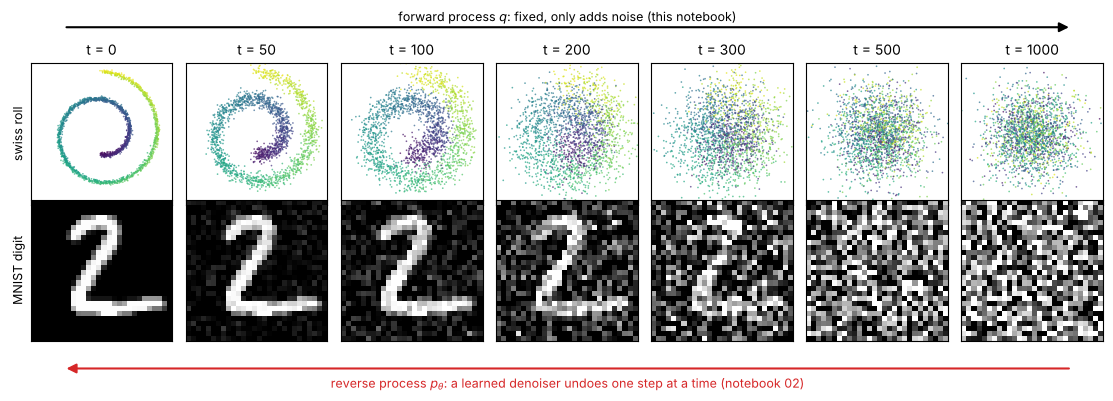

In [3]:
show_t = [0, 50, 100, 200, 300, 500, 1000]
snaps_roll = forward_chain(x_roll, betas_lin, record=show_t)
snaps_digit = forward_chain(digit, betas_lin, record=show_t)

fig, axes = plt.subplots(2, len(show_t), figsize=(1.6 * len(show_t), 3.9))
for j, t in enumerate(show_t):
    n_show = 2000                                # plotting more points only bloats the figure
    dm.scatter2d(snaps_roll[t][:n_show], ax=axes[0, j], c=roll_colour[:n_show], cmap="viridis", s=1.5,
                 alpha=0.7, lim=3.2, title=f"t = {t}")
    # clamp to the image range [-1, 1] for display, as when saving an image file
    axes[1, j].imshow(snaps_digit[t][0, 0].clamp(-1, 1).cpu(), cmap="gray", vmin=-1, vmax=1)
    axes[1, j].set_xticks([]); axes[1, j].set_yticks([])
axes[0, 0].set_ylabel("swiss roll")
axes[1, 0].set_ylabel("MNIST digit")
plt.tight_layout(rect=(0, 0.07, 1, 0.9))
fig.patches.append(FancyArrowPatch((0.06, 0.925), (0.96, 0.925), transform=fig.transFigure,
                                   arrowstyle="-|>", mutation_scale=14, lw=1.5, color="k"))
fig.text(0.51, 0.94, r"forward process $q$: fixed, only adds noise (this notebook)", ha="center")
fig.patches.append(FancyArrowPatch((0.96, 0.05), (0.06, 0.05), transform=fig.transFigure,
                                   arrowstyle="-|>", mutation_scale=14, lw=1.5, color="tab:red"))
fig.text(0.51, 0.0, r"reverse process $p_\theta$: a learned denoiser undoes one step at a time (notebook 02)",
         ha="center", color="tab:red")
plt.show()

**Top:** a 2-D swiss roll, coloured by position along the roll. **Bottom:** an MNIST digit. Both are
destroyed gradually. Around the middle of the chain the roll has become a blob and the digit can no
longer be read, and at $t=T$ both look like standard Gaussian noise. The colours also get mixed: a
noisy point no longer reveals where on the roll it came from. That lost information is what the
reverse model has to fill back in, using what it learned about the data.

## 2 · One step, and why it shrinks the signal

A single step is the Gaussian transition kernel

$$q(x_t\mid x_{t-1}) = \mathcal N\!\big(x_t;\ \sqrt{1-\beta_t}\,x_{t-1},\ \beta_t I\big),$$

and the whole chain is $q(x_{1:T}\mid x_0)=\prod_{t=1}^T q(x_t\mid x_{t-1})$, a Markov chain (a
discretised Ornstein–Uhlenbeck process). We write $\alpha_t := 1-\beta_t$ and
$\bar\alpha_t := \prod_{s=1}^t \alpha_s$ (with $\bar\alpha_0=1$).

**Why the factor $\sqrt{1-\beta_t}$?** Follow the variance of one coordinate. The noise is independent of
$x_{t-1}$, so

$$\operatorname{Var}[x_t] = (1-\beta_t)\operatorname{Var}[x_{t-1}] + \beta_t
\quad\Longleftrightarrow\quad
\operatorname{Var}[x_t]-1 = (1-\beta_t)\big(\operatorname{Var}[x_{t-1}]-1\big).$$

Unit variance is a fixed point, and any deviation from it decays geometrically:
$\operatorname{Var}[x_t] = 1 + \bar\alpha_t\,(\operatorname{Var}[x_0]-1)$. The mean decays too:
$\mathbb E[x_t]=\sqrt{\bar\alpha_t}\,\mathbb E[x_0]$. The process is therefore **variance preserving (VP)**:
$x_t$ stays at unit scale and ends up at $\mathcal N(0,I)$ *whatever the data were*.

Without the shrink factor ($x_t = x_{t-1}+\sqrt{\beta_t}\varepsilon_t$), the variances simply add:
$\operatorname{Var}[x_t]=\operatorname{Var}[x_0]+\sum_{s\le t}\beta_s$. The variance grows without bound and the data
are never actually removed, only drowned. A useful summary is the **signal fraction**: the share of
$\operatorname{Var}[x_t]$ that comes from the data. It is $\bar\alpha_t v_0/(\bar\alpha_t v_0 + 1-\bar\alpha_t)$
for VP and $v_0/(v_0+\sum_{s\le t}\beta_s)$ without shrinking, where $v_0=\operatorname{Var}[x_0]$.

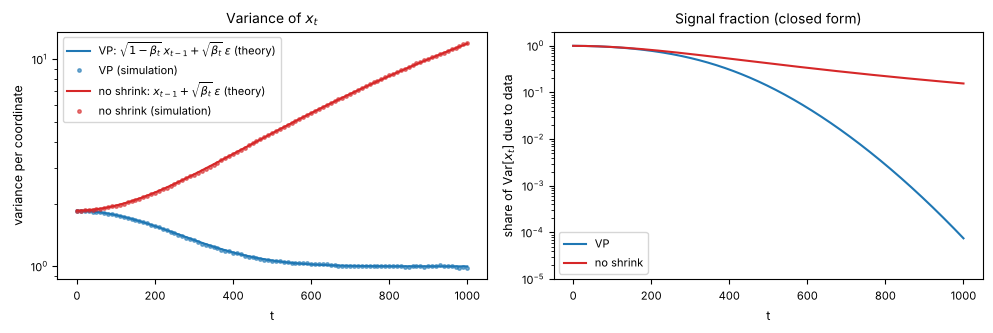

data variance v0 = 1.858
at t = T:  VP variance = 0.983, signal fraction = 7.5e-05
           no-shrink variance = 11.98, signal fraction = 0.156


In [4]:
rec = list(range(0, T + 1, 10))
chain_vp = forward_chain(x_roll, betas_lin, record=rec, shrink=True)
chain_ns = forward_chain(x_roll, betas_lin, record=rec, shrink=False)
# per-coordinate variance, averaged over the two coordinates
var_vp = np.array([chain_vp[t].var(0).mean().item() for t in rec])
var_ns = np.array([chain_ns[t].var(0).mean().item() for t in rec])

abar_lin = torch.cumprod(1 - betas_lin, 0)          # abar_lin[t] = bar-alpha_t, abar_lin[0] = 1
v0 = x_roll.var(0).mean().item()
cum_beta = torch.cumsum(betas_lin, 0)
theory_var_vp = 1 + abar_lin * (v0 - 1)
theory_var_ns = v0 + cum_beta
signal_vp = abar_lin * v0 / (abar_lin * v0 + 1 - abar_lin)
signal_ns = v0 / (v0 + cum_beta)

tt = np.arange(T + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
ax.plot(tt, theory_var_vp, color=C_VP, label=r"VP: $\sqrt{1-\beta_t}\,x_{t-1}+\sqrt{\beta_t}\,\varepsilon$ (theory)")
ax.plot(rec, var_vp, "o", ms=2.5, color=C_VP, alpha=0.6, label="VP (simulation)")
ax.plot(tt, theory_var_ns, color=C_VE, label=r"no shrink: $x_{t-1}+\sqrt{\beta_t}\,\varepsilon$ (theory)")
ax.plot(rec, var_ns, "o", ms=2.5, color=C_VE, alpha=0.6, label="no shrink (simulation)")
ax.set(yscale="log", xlabel="t", ylabel="variance per coordinate", title=r"Variance of $x_t$")
ax.legend()
ax = axes[1]
ax.plot(tt, signal_vp, color=C_VP, label="VP")
ax.plot(tt, signal_ns, color=C_VE, label="no shrink")
ax.set(yscale="log", ylim=(1e-5, 2), xlabel="t", ylabel="share of Var[$x_t$] due to data",
       title="Signal fraction (closed form)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"data variance v0 = {v0:.3f}")
print(f"at t = T:  VP variance = {var_vp[-1]:.3f}, signal fraction = {signal_vp[-1]:.1e}")
print(f"           no-shrink variance = {var_ns[-1]:.2f}, signal fraction = {signal_ns[-1]:.3f}")

**Left:** with the shrink factor, the variance relaxes to exactly 1 (simulation dots on the theory
line). Without it, the variance grows by $\sum\beta_t$. **Right:** VP removes the data
*exponentially fast* ($\bar\alpha_t\approx e^{-\sum_s\beta_s}$), while adding the same noise without
shrinking leaves a sizeable share of the data in $x_T$. To erase the data without shrinking, the
total noise variance must be huge compared with the data's scale. That is the "variance exploding"
family (section 9).

> **Practical gotcha: data scale.** VP assumes data of roughly unit scale. That is why images are
> mapped to $[-1,1]$, and why latent diffusion rescales its latents (notebook 09). If you multiply
> your data by 10, the same schedule removes it much later (try it in Exercise 2).

## 3 · Jumping to any $t$ in one shot: $q(x_t\mid x_0)$

**Claim.** $q(x_t\mid x_0)=\mathcal N\big(\sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t)\,I\big)$, i.e.

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\qquad \varepsilon\sim\mathcal N(0,I).$$

**Proof by induction.** It holds at $t=1$ ($\bar\alpha_1=\alpha_1$). Suppose
$x_{t-1}=\sqrt{\bar\alpha_{t-1}}\,x_0+\sqrt{1-\bar\alpha_{t-1}}\,\bar\varepsilon$. Then

$$x_t=\sqrt{\alpha_t}\,x_{t-1}+\sqrt{1-\alpha_t}\,\varepsilon_t
     =\sqrt{\bar\alpha_t}\,x_0+\underbrace{\sqrt{\alpha_t(1-\bar\alpha_{t-1})}\,\bar\varepsilon+\sqrt{1-\alpha_t}\,\varepsilon_t}_{\text{sum of independent zero-mean Gaussians}}.$$

Two independent Gaussians merge into one whose variance is the sum of theirs:
$\alpha_t-\bar\alpha_t+1-\alpha_t = 1-\bar\alpha_t$. $\square$

Two readings of this result:
- $\sqrt{\bar\alpha_t}$ is the **signal amplitude** and $\sqrt{1-\bar\alpha_t}$ the **noise amplitude**. Their squares
  always sum to 1 (variance preserving).
- **Training never runs the chain.** A training step needs random pairs $(x_0, x_t)$ at random $t$. The closed
  form gives $x_t$ in $O(1)$ instead of $O(t)$, and it also returns the exact noise $\varepsilon$ that was added,
  which becomes the regression target in notebook 02.

Below, `q_sample` takes one time index per example. The coefficient vector must be reshaped from
`(B,)` to `(B, 1, ..., 1)` so that it broadcasts over the data dimensions.

> **Gotcha: broadcasting.** `abar[t] * x0`, with `abar[t]` of shape `(B,)` and `x0` of shape `(B, 1, 28, 28)`,
> lines `(B,)` up with the *last* axis (width 28). It raises an error, or, worse, silently does the
> wrong thing when the batch size happens to equal 28.

In [5]:
def q_sample(x0, t, abar, noise=None):
    """One-shot sample from q(x_t | x_0) = N(sqrt(abar_t) x0, (1 - abar_t) I).

    x0   : (B, ...) clean data
    t    : (B,) long tensor of maths times in {0, ..., T} (one per example)
    abar : (T+1,) tensor with abar[t] = bar-alpha_t and abar[0] = 1
    """
    if noise is None:
        noise = torch.randn_like(x0)
    a = abar.float().to(x0.device)[t]                    # (B,)
    a = a.view(-1, *([1] * (x0.ndim - 1)))               # (B, 1, ..., 1): broadcast over data dims
    return a.sqrt() * x0 + (1 - a).sqrt() * noise


# --- CHECK 1: our schedule maths and q_sample agree with dmtools (note the index shift) ---------
dm_sched = dm.NoiseSchedule(T, "linear", device=device)
assert torch.allclose(betas_lin[1:].float(), dm_sched.betas.cpu())
assert torch.allclose(abar_lin[1:].float(), dm_sched.alpha_bars.cpu(), rtol=1e-6, atol=1e-9)

x0_b = x_roll[:16]
t_b = torch.randint(1, T + 1, (16,), device=device)    # maths time 1..T
noise_b = torch.randn_like(x0_b)
ours = q_sample(x0_b, t_b, abar_lin, noise_b)
theirs = dm_sched.q_sample(x0_b, t_b - 1, noise_b)    # dmtools index = maths t - 1
assert torch.allclose(ours, theirs, atol=1e-6)
# the classic bug: passing maths t straight to dmtools (clamped, since t = T would even be out of range)
wrong = (dm_sched.q_sample(x0_b, t_b.clamp(max=T - 1), noise_b) - ours).abs().max()
print("schedule + q_sample match dmtools (with dmtools' t = our t - 1)")
print(f"forgetting the shift silently changes x_t by up to {wrong.item():.4f} (no error is raised)")

schedule + q_sample match dmtools (with dmtools' t = our t - 1)
forgetting the shift silently changes x_t by up to 0.0043 (no error is raised)


Now the real test: run the chain step by step up to $t$, sample $x_t$ in one shot from the same
$x_0$'s, and compare the two distributions. We compare means and covariances with the closed form
$\mathbb E[x_t]=\sqrt{\bar\alpha_t}\,\mathbb E[x_0]$ and
$\operatorname{Cov}[x_t]=\bar\alpha_t\operatorname{Cov}[x_0]+(1-\bar\alpha_t)I$, and we use the kernel two-sample statistic
`dm.mmd_rbf` (0 means identical distributions). Its finite-sample noise floor is estimated by comparing two
*independent* one-shot draws.

   t  abar_t |      mean: chain / one-shot / theory       | Var[x1]: chain / one-shot / theory | MMD chain-vs-1shot  MMD floor


  50   0.971 | (+0.384,+0.030) (+0.384,+0.030) (+0.384,+0.030) | 1.756 / 1.756 / 1.755        |           2.64e-03   2.54e-03


 200   0.659 | (+0.318,+0.025) (+0.312,+0.025) (+0.316,+0.025) | 1.524 / 1.522 / 1.513        |           5.28e-03   4.58e-03


 500   0.079 | (+0.109,+0.007) (+0.114,+0.014) (+0.109,+0.009) | 1.061 / 1.074 / 1.061        |           5.04e-03   4.47e-03


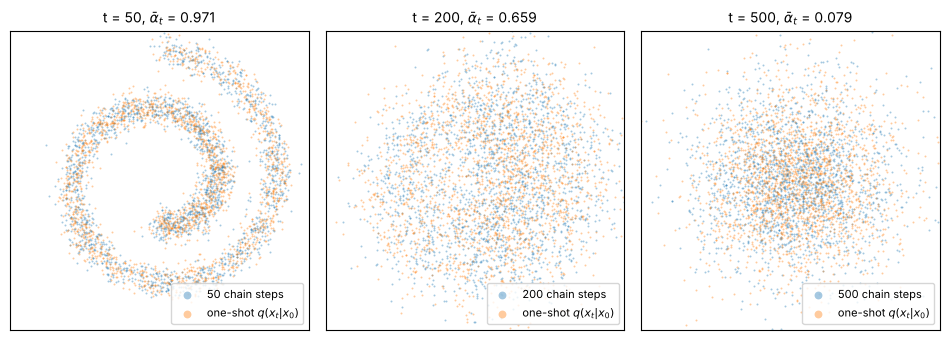

In [6]:
check_t = [50, 200, 500]
chain = forward_chain(x_roll, betas_lin, record=check_t)
n_mmd = 1000 if FAST else 2000      # MMD needs an (2n x 2n) kernel matrix, keep it moderate
print(f"{'t':>4} {'abar_t':>7} | {'mean: chain / one-shot / theory':^42} | "
      f"{'Var[x1]: chain / one-shot / theory':^34} | {'MMD chain-vs-1shot':>18} {'MMD floor':>10}")
one_shot = {}
for t in check_t:
    t_vec = torch.full((N,), t, device=device, dtype=torch.long)
    one_shot[t] = q_sample(x_roll, t_vec, abar_lin)
    one_shot_b = q_sample(x_roll, t_vec, abar_lin)            # independent draw: MMD noise floor
    a = abar_lin[t].item()
    m_th = math.sqrt(a) * x_roll.mean(0)
    v_th = a * x_roll[:, 0].var() + (1 - a)
    ch, os_ = chain[t], one_shot[t]
    mmd = dm.mmd_rbf(ch.cpu(), os_.cpu(), max_n=n_mmd)
    mmd0 = dm.mmd_rbf(one_shot_b.cpu(), os_.cpu(), max_n=n_mmd)
    fmt = lambda v: f"({v[0]:+.3f},{v[1]:+.3f})"
    print(f"{t:4d} {a:7.3f} | {fmt(ch.mean(0))} {fmt(os_.mean(0))} {fmt(m_th)} | "
          f"{ch[:, 0].var():.3f} / {os_[:, 0].var():.3f} / {v_th:.3f}        | {mmd:18.2e} {mmd0:10.2e}")

fig, axes = plt.subplots(1, len(check_t), figsize=(3.2 * len(check_t), 3.3))
for ax, t in zip(axes, check_t):
    dm.scatter2d(chain[t][:2000], ax=ax, s=2, alpha=0.4, c=C_VP, lim=3.2, label=f"{t} chain steps")
    dm.scatter2d(one_shot[t][:2000], ax=ax, s=2, alpha=0.4, c=C_COS, lim=3.2, label="one-shot $q(x_t|x_0)$",
                 title=rf"t = {t}, $\bar\alpha_t$ = {abar_lin[t]:.3f}")
    ax.legend(loc="lower right", markerscale=4)
plt.tight_layout()
plt.show()

The two clouds overlap at every $t$. Means and variances agree with the closed form up to Monte
Carlo error, and the MMD between "chain" and "one shot" is of the same order as the MMD between two
independent one-shot draws, i.e. at the noise floor. From now on we never need to run the chain.

## 4 · Noise schedules: what really matters is the SNR curve

The schedule $\beta_1,\dots,\beta_T$ is a design choice. Equivalently, we can choose the curve
$\bar\alpha_t$, or the **signal-to-noise ratio** and its logarithm

$$\mathrm{SNR}(t)=\frac{\bar\alpha_t}{1-\bar\alpha_t},\qquad \lambda_t=\log\mathrm{SNR}(t)\quad(\text{so } \bar\alpha_t=\operatorname{sigmoid}(\lambda_t)).$$

Two classic choices:
- **Linear** (Ho et al. 2020): $\beta_t$ linear from $10^{-4}$ to $0.02$ at $T=1000$.
- **Cosine** (Nichol & Dhariwal 2021): specify $\bar\alpha$ directly,
  $\bar\alpha_t=f(t)/f(0)$ with $f(t)=\cos^2\!\big(\tfrac{t/T+s}{1+s}\cdot\tfrac{\pi}{2}\big)$. The small offset $s=0.008$
  keeps $\beta_1$ from being vanishingly small. Then $\beta_t = 1-\bar\alpha_t/\bar\alpha_{t-1}$, **clipped at 0.999**,
  because the formula gives $\beta_T = 1$ exactly (a singular last step).

Since $q(x_t\mid x_0)$ depends on $t$ *only through* $\bar\alpha_t$ (equivalently $\lambda_t$), two schedules that pass
through the same noise level produce exactly the same $x_t$ distribution there. A schedule only decides
**how the $T$ steps are spread over noise levels**. That spread decides where training effort and
sampling steps go. (Kingma et al. 2021 show that, in continuous time, even the ELBO depends on the
schedule only through its endpoints $\lambda_{\max}$ and $\lambda_{\min}$.) It also means $T$ is just a
discretisation of a continuous curve $\lambda(\tau)$, $\tau=t/T\in[0,1]$. `dm.NoiseSchedule` keeps the linear
schedule's continuous curve fixed when you change $T$ by rescaling $\beta_t\to\beta_t\cdot 1000/T$, so that
$\bar\alpha(\tau)\approx\exp(-\sum_s\beta_s)$ stays put. **Respacing** is more robust: keep a subset of the
noise levels $\bar\alpha_{\tau_0}>\bar\alpha_{\tau_1}>\dots$ of a fine schedule and recompute $\beta_j = 1-\bar\alpha_{\tau_j}/\bar\alpha_{\tau_{j-1}}$.

In [7]:
def make_schedule(kind="linear", T=1000, beta_start=1e-4, beta_end=0.02, s=0.008):
    """(betas, abar) as float64 tensors of length T+1, indexed by maths time (betas[0]=0, abar[0]=1)."""
    if kind == "linear":
        scale = 1000.0 / T          # same continuous-time process for every T (the dmtools convention)
        b = torch.linspace(beta_start * scale, beta_end * scale, T, dtype=torch.float64)
    elif kind == "cosine":
        tau = torch.arange(T + 1, dtype=torch.float64) / T
        f = torch.cos((tau + s) / (1 + s) * math.pi / 2) ** 2
        abar_c = f / f[0]
        b = (1 - abar_c[1:] / abar_c[:-1]).clamp(max=0.999)   # beta_T would be exactly 1
    else:
        raise ValueError(kind)
    betas = torch.cat([torch.zeros(1, dtype=torch.float64), b])
    return betas, torch.cumprod(1 - betas, 0)


def respace(abar, n_steps):
    """Keep n_steps+1 evenly spaced noise levels (incl. t=0 and t=T) of a fine schedule; recompute betas."""
    idx = torch.linspace(0, len(abar) - 1, n_steps + 1, dtype=torch.float64).round().long()
    ab = abar[idx]
    betas = torch.cat([torch.zeros(1, dtype=ab.dtype), 1 - ab[1:] / ab[:-1]])
    return betas, ab


def log_snr(abar):
    return torch.log(abar) - torch.log1p(-abar)


betas_cos, abar_cos = make_schedule("cosine", T)
# --- CHECK: hand-written schedules == dmtools for both kinds and several T ------------------------
for kind in ["linear", "cosine"]:
    for T_ in [1000, 250, 50]:
        b, ab = make_schedule(kind, T_)
        ref = dm.NoiseSchedule(T_, kind)
        assert torch.allclose(b[1:].float(), ref.betas, rtol=1e-5, atol=1e-8), (kind, T_)
        assert torch.allclose(ab[1:].float(), ref.alpha_bars, rtol=1e-4, atol=1e-9), (kind, T_)
        assert torch.allclose(log_snr(ab[1:]).float(), ref.log_snr, rtol=1e-4, atol=1e-4), (kind, T_)
print("make_schedule matches dm.NoiseSchedule (linear & cosine, T = 1000, 250, 50)")
for name, ab in [("linear", abar_lin), ("cosine", abar_cos)]:
    print(f"{name:>6}: abar_T = {ab[-1]:.1e}, log-SNR range [{log_snr(ab[1:]).min():.1f}, "
          f"{log_snr(ab[1:]).max():.1f}], fraction of steps with abar_t < 0.01 (almost pure noise): "
          f"{(ab[1:] < 0.01).double().mean():.0%}, with |log-SNR| < 5: {(log_snr(ab[1:]).abs() < 5).double().mean():.0%}")
print(f"gotcha: dm.NoiseSchedule(10, 'linear').betas.max() = {dm.NoiseSchedule(10, 'linear').betas.max():.2f} "
      f"(> 1 is invalid: rescaling by 1000/T breaks down for T <= 20, use respacing instead)")

make_schedule matches dm.NoiseSchedule (linear & cosine, T = 1000, 250, 50)
linear: abar_T = 4.0e-05, log-SNR range [-10.1, 9.2], fraction of steps with abar_t < 0.01 (almost pure noise): 33%, with |log-SNR| < 5: 68%
cosine: abar_T = 2.4e-09, log-SNR range [-19.8, 10.1], fraction of steps with abar_t < 0.01 (almost pure noise): 6%, with |log-SNR| < 5: 90%
gotcha: dm.NoiseSchedule(10, 'linear').betas.max() = 2.00 (> 1 is invalid: rescaling by 1000/T breaks down for T <= 20, use respacing instead)


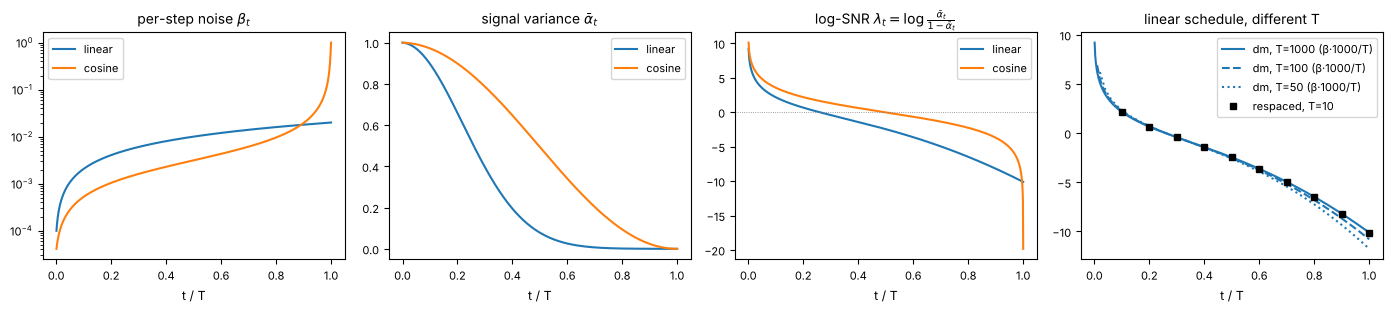

In [8]:
tau = torch.arange(T + 1) / T
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for name, b, ab, c in [("linear", betas_lin, abar_lin, C_LIN), ("cosine", betas_cos, abar_cos, C_COS)]:
    axes[0].plot(tau[1:], b[1:], color=c, label=name)
    axes[1].plot(tau, ab, color=c, label=name)
    axes[2].plot(tau[1:], log_snr(ab[1:]), color=c, label=name)
axes[0].set(yscale="log", xlabel="t / T", title=r"per-step noise $\beta_t$")
axes[1].set(xlabel="t / T", title=r"signal variance $\bar\alpha_t$")
axes[2].set(xlabel="t / T", title=r"log-SNR $\lambda_t=\log\frac{\bar\alpha_t}{1-\bar\alpha_t}$")
axes[2].axhline(0, color="gray", lw=0.6, ls=":")
for ax in axes[:3]:
    ax.legend()
# changing T while keeping the continuous process
for T_, ls in [(1000, "-"), (100, "--"), (50, ":")]:
    ref = dm.NoiseSchedule(T_, "linear")
    axes[3].plot((torch.arange(T_) + 1) / T_, ref.log_snr, ls, color=C_LIN, label=f"dm, T={T_} (β·1000/T)")
_, ab10 = respace(abar_lin, 10)
axes[3].plot(torch.arange(1, 11) / 10, log_snr(ab10[1:]), "s", color="k", ms=4, label="respaced, T=10")
axes[3].set(xlabel="t / T", title="linear schedule, different T")
axes[3].legend()
plt.tight_layout()
plt.show()

- **$\beta_t$ (log scale):** the cosine schedule starts with smaller steps and ends with much larger ones (the
  last step is clipped at 0.999).
- **$\bar\alpha_t$:** under the linear schedule the signal is essentially gone by $t/T\approx 0.6$. The last
  third of the steps therefore operate on almost pure noise, which is wasted effort both in training
  and in sampling. The cosine curve decays smoothly all the way to $T$.
- **log-SNR:** both curves drop steeply at first and then fall roughly linearly, but the cosine curve sits higher
  (it only plunges below the linear one in the last few percent of steps). It therefore spends more of its steps
  in the middle range ($|\lambda|<5$, see the printout), where the data are actually being transformed
  (section 6), and fewer at the extremes.
- **Changing $T$:** the rescaled linear schedules for $T=100$ and $T=50$ follow the $T=1000$ curve closely and drift
  apart only at the low-SNR end. The gap comes from $\prod(1-\beta)\neq e^{-\sum\beta}$ when the steps are large.
  Respacing reproduces the curve exactly by construction.

Now look at an image. Below, the same digit is noised at the same $t/T$ under both schedules, using
the **same** noise $\varepsilon$, so the only difference is $\bar\alpha_t$.

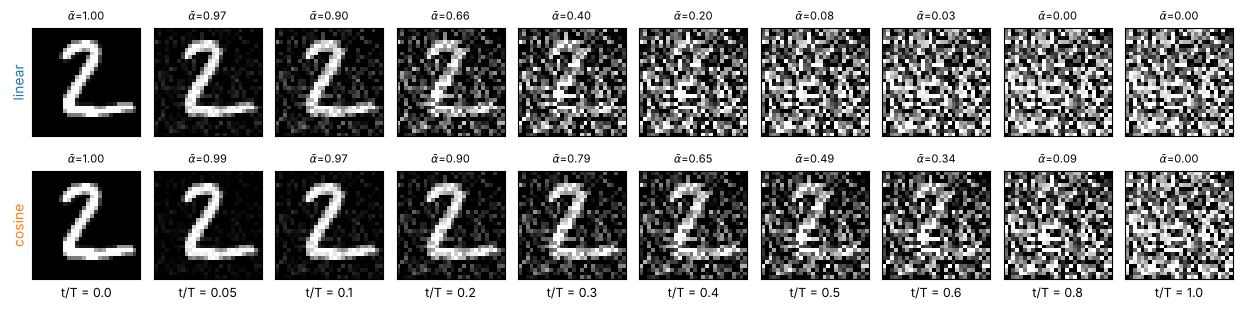

In [9]:
frac_show = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
eps_digit = torch.randn_like(digit)                       # one shared noise draw
fig, axes = plt.subplots(2, len(frac_show), figsize=(1.25 * len(frac_show), 3.2))
for row, (name, ab) in enumerate([("linear", abar_lin), ("cosine", abar_cos)]):
    for j, f in enumerate(frac_show):
        t = int(round(f * T))
        x_t = q_sample(digit, torch.tensor([t], device=device), ab, eps_digit)
        axes[row, j].imshow(x_t[0, 0].clamp(-1, 1).cpu(), cmap="gray", vmin=-1, vmax=1)
        axes[row, j].set_xticks([]); axes[row, j].set_yticks([])
        axes[row, j].set_title(rf"$\bar\alpha$={ab[t]:.2f}", fontsize=8)
        if row == 1:
            axes[row, j].set_xlabel(f"t/T = {f}")
    axes[row, 0].set_ylabel(name, color=C_LIN if name == "linear" else C_COS, fontsize=10)
plt.tight_layout()
plt.show()

Under the linear schedule (top) the digit is barely readable by $t/T\approx 0.4$ and gone by $0.5$. Every
later column is pure noise to the eye, yet half of the 1000 steps live there. The cosine schedule
(bottom) keeps the digit recognisable for much longer and destroys it evenly. The linear schedule is
nonetheless what DDPM and our MNIST models (notebooks 05–07) use: it works, it just wastes steps.
For small $28\times28$ images this "destroys too early" effect is strongest, which was a main motivation
for the cosine schedule.

> **Gotchas.** (i) Report and compare schedules by their **log-SNR curve**, not by $\beta$. (ii) Neither schedule
> reaches $\bar\alpha_T=0$ exactly (see the printout above). A tiny bit of signal survives in $x_T$ at
> training time, while sampling starts from pure noise (Exercise 1). (iii) The cosine $\beta_T$ is clipped. Without
> the clip $\alpha_T=0$, and anything that divides by $\sqrt{\alpha_t}$ blows up.

## 5 · The noised data distribution $q_t(x)$

So far we noised individual points. The distribution of $x_t$ over *all* data is the marginal

$$q_t(x) = \int q(x_t=x\mid x_0)\,p_{\text{data}}(x_0)\,dx_0 ,$$

i.e. the data distribution shrunk by $\sqrt{\bar\alpha_t}$ and then blurred by a Gaussian of variance
$1-\bar\alpha_t$. Later notebooks learn its score $\nabla_x\log q_t(x)$. For real data $q_t$ is
intractable, but for a **Gaussian mixture** it is exact. If $x_0\sim\mathcal N(\mu_k,\Sigma_k)$, then
$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\varepsilon$ is a linear map of a Gaussian plus independent
Gaussian noise, so

$$p_{\text{data}}=\sum_k w_k\,\mathcal N(\mu_k,\Sigma_k)\quad\Longrightarrow\quad
q_t=\sum_k w_k\,\mathcal N\!\big(\sqrt{\bar\alpha_t}\,\mu_k,\ \bar\alpha_t\Sigma_k+(1-\bar\alpha_t)I\big).$$

The weights are unchanged, the means shrink, and the covariances inflate towards $I$. This GMM
"laboratory" is used throughout the tutorial (`dm.GaussianMixture.noised`), because it lets us
separate a model's errors from a sampler's errors.

In [10]:
def noised_gmm(gmm, abar_t):
    """Exact marginal q_t of a Gaussian mixture under x_t = sqrt(abar) x0 + sqrt(1-abar) eps."""
    I = torch.eye(gmm.d, dtype=torch.float64)
    return dm.GaussianMixture(gmm.weights, math.sqrt(abar_t) * gmm.means,
                              abar_t * gmm.covs + (1 - abar_t) * I)


gmm2d = dm.default_gmm()
# --- CHECK 1: same parameters as dmtools' implementation --------------------------------------
for a in [0.9, 0.3, 0.01]:
    ours, ref = noised_gmm(gmm2d, a), gmm2d.noised(a)
    assert torch.allclose(ours.means, ref.means) and torch.allclose(ours.covs, ref.covs)
print("noised_gmm matches dm.GaussianMixture.noised")

# --- CHECK 2: Monte Carlo noised samples vs the analytic marginal -------------------------------
# Average log-density E[log q_t(x)] under (a) noised data samples and (b) samples drawn from the
# analytic q_t. If the two distributions agree, these averages agree within Monte Carlo error.
show_t2 = [0, 50, 100, 150, 250, 1000]
x0_gmm = gmm2d.sample(N).to(device)
mc_samples = {}
print(f"{'t':>5} {'abar':>6} | {'E log q_t: noised data':>24} | {'E log q_t: analytic samples':>28}")
for t in show_t2:
    q_t = noised_gmm(gmm2d, abar_lin[t].item())
    mc_samples[t] = q_sample(x0_gmm, torch.full((N,), t, device=device), abar_lin).cpu()
    lp_mc = q_t.log_prob(mc_samples[t])
    lp_an = q_t.log_prob(q_t.sample(N))
    se = lambda v: 2 * v.std().item() / math.sqrt(len(v))
    print(f"{t:5d} {abar_lin[t]:6.3f} | {lp_mc.mean():10.3f} +- {se(lp_mc):.3f}       "
          f"| {lp_an.mean():12.3f} +- {se(lp_an):.3f}")

noised_gmm matches dm.GaussianMixture.noised
    t   abar |   E log q_t: noised data |  E log q_t: analytic samples


    0  1.000 |     -0.959 +- 0.017       |       -0.971 +- 0.017


   50  0.971 |     -1.825 +- 0.016       |       -1.829 +- 0.016


  100  0.897 |     -2.549 +- 0.013       |       -2.535 +- 0.013


  150  0.788 |     -2.783 +- 0.011       |       -2.789 +- 0.011


  250  0.524 |     -2.859 +- 0.012       |       -2.860 +- 0.013


 1000  0.000 |     -2.830 +- 0.014       |       -2.836 +- 0.014


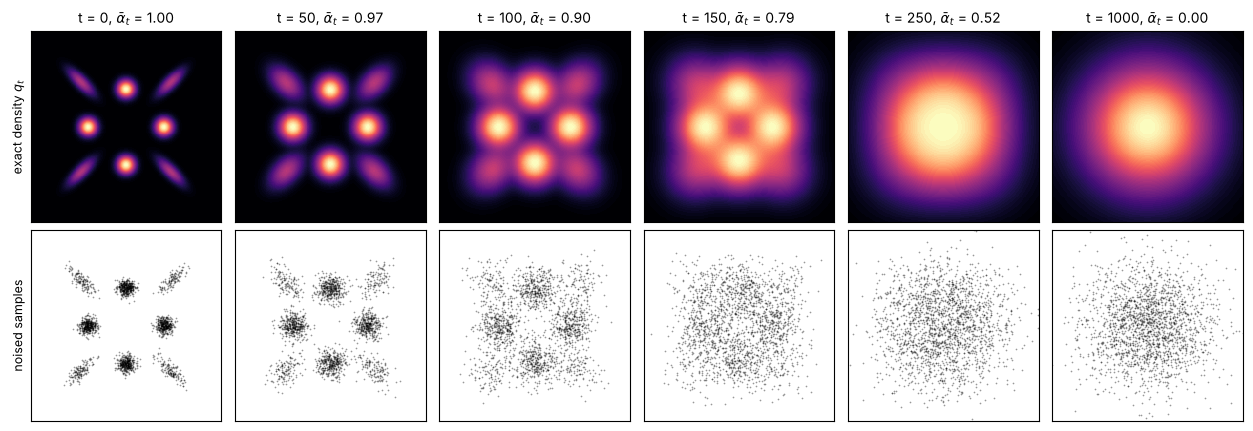

In [11]:
lim = 3.0
axis_pts = torch.linspace(-lim, lim, 200, dtype=torch.float64)
GX, GY = torch.meshgrid(axis_pts, axis_pts, indexing="xy")
grid2d = torch.stack([GX.flatten(), GY.flatten()], 1)
fig, axes = plt.subplots(2, len(show_t2), figsize=(2.1 * len(show_t2), 4.4))
for j, t in enumerate(show_t2):
    dens = noised_gmm(gmm2d, abar_lin[t].item()).log_prob(grid2d).exp().reshape(200, 200)
    axes[0, j].imshow(dens, origin="lower", extent=[-lim, lim, -lim, lim], cmap=CMAP_DENSITY,
                      norm=PowerNorm(0.5), interpolation="nearest")
    axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
    axes[0, j].set_title(rf"t = {t}, $\bar\alpha_t$ = {abar_lin[t]:.2f}")
    dm.scatter2d(mc_samples[t][:2000], ax=axes[1, j], s=1.5, alpha=0.4, c="k", lim=lim)
axes[0, 0].set_ylabel("exact density $q_t$")
axes[1, 0].set_ylabel("noised samples")
plt.tight_layout()
plt.show()

Top: the exact density $q_t$ (square-root colour scale, normalised per panel). Bottom: data points
noised with `q_sample`. They match. The thin elongated components blur first, then neighbouring
modes merge into a ring, and finally the ring fills in and contracts into a single isotropic Gaussian.

The same story in 1-D gives the most useful single picture of diffusion. We build a 1-D mixture with
**hierarchical** structure: two "families" of narrow modes (two on the left, three on the right). We
draw $q_t(x)$ as a heatmap over $(t, x)$ and overlay a few forward trajectories. Because $q_t$ depends
on $t$ only through $\lambda_t$, the third panel plots the same density against log-SNR. That panel is
the same for every schedule.

In [12]:
gmm1d = dm.GaussianMixture(weights=[0.25, 0.20, 0.20, 0.15, 0.20],
                           means=[[-1.5], [-0.95], [0.6], [1.05], [1.5]],
                           covs=torch.tensor([0.08, 0.08, 0.07, 0.07, 0.07]) ** 2)
SIDE = torch.tensor([0, 0, 1, 1, 1])           # coarse label of each component: left / right family
xg = torch.linspace(-3, 3, 400, dtype=torch.float64)[:, None]
t_cols = list(range(0, T + 1, 5))
lam_cols = torch.linspace(10, -10, 201, dtype=torch.float64)   # log-SNR grid, high -> low SNR


def density_map(abars):
    """Matrix of q_t(x) on the x-grid (rows) for each abar (columns)."""
    return np.stack([gmm1d.noised(float(a)).log_prob(xg).exp().numpy() for a in abars], 1)


maps = {"linear": density_map(abar_lin[t_cols]), "cosine": density_map(abar_cos[t_cols]),
        "log-SNR": density_map(torch.sigmoid(lam_cols))}
# a few forward trajectories (the same 8 starting points under each schedule)
x0_paths = gmm1d.sample(4, generator=torch.Generator().manual_seed(3))
paths = {}
for name, b in [("linear", betas_lin), ("cosine", betas_cos)]:
    snaps = forward_chain(x0_paths, b, record=range(T + 1))
    paths[name] = torch.stack([snaps[t][:, 0] for t in range(T + 1)]).numpy()   # (T+1, 4)

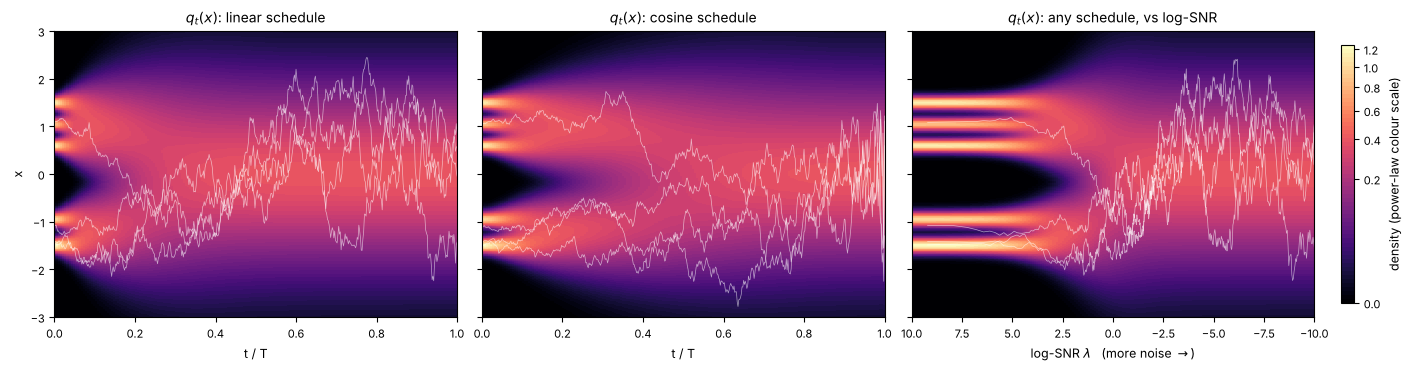

In [13]:
vmax = max(m.max() for m in maps.values())
panels = [  # (density map, x-range, x-label, title, trajectory x-coordinates, trajectories)
    ("linear", (0, 1), "t / T", "linear schedule", tau.numpy(), paths["linear"]),
    ("cosine", (0, 1), "t / T", "cosine schedule", tau.numpy(), paths["cosine"]),
    ("log-SNR", (10, -10), r"log-SNR $\lambda$   (more noise $\rightarrow$)", "any schedule, vs log-SNR",
     log_snr(abar_lin[1:]).numpy(), paths["linear"][1:]),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True, layout="constrained")
for ax, (name, (x_lo, x_hi), xlabel, title, path_x, path_y) in zip(axes, panels):
    im = ax.imshow(maps[name], origin="lower", aspect="auto", extent=[x_lo, x_hi, -3, 3], cmap=CMAP_DENSITY,
                   norm=PowerNorm(0.4, vmin=0, vmax=vmax), interpolation="nearest")
    ax.plot(path_x[::2], path_y[::2], color="w", lw=0.5, alpha=0.6)    # every 2nd step is plenty at this width
    ax.set(xlabel=xlabel, xlim=(x_lo, x_hi), ylim=(-3, 3), title=f"$q_t(x)$: {title}")
axes[0].set_ylabel("x")
fig.colorbar(im, ax=axes, shrink=0.9, pad=0.01, label="density (power-law colour scale)")
plt.show()

The data distribution (left edge of each panel) "melts" smoothly into $\mathcal N(0,1)$. It does so
**hierarchically**: the narrow modes inside each family merge first, and the two families merge into
one bump only later. Under the linear schedule all the interesting structure is gone within roughly the
first quarter of the steps. The cosine schedule stretches the same events over about twice as much of the
time axis. Plotted against
log-SNR (right), both schedules give exactly this one picture. The white lines are individual forward
trajectories: jittery random walks pulled towards 0 (an Ornstein–Uhlenbeck process), which forget where
they started.

## 6 · What is destroyed, and when

Take the view of a **Bayesian observer** who sees only $x_t$, knows the generative model, and wants to
infer the latent cause: which mixture component $k$ produced the data point. By Bayes' rule,

$$p(k\mid x_t)=\frac{w_k\,\mathcal N\big(x_t;\sqrt{\bar\alpha_t}\mu_k,\ \bar\alpha_t\sigma_k^2+1-\bar\alpha_t\big)}{\sum_j w_j\,\mathcal N(\dots)} ,$$

which is exactly the *responsibilities* of the noised GMM. Its expected entropy
$H(K\mid X_t)=\mathbb E_{x_t\sim q_t}\big[H(p(\cdot\mid x_t))\big]$ measures how much the observer is still
missing. Because $K\to X_0\to X_t\to X_{t+1}$ is a Markov chain, the data-processing inequality says the
information $I(K;X_t)=H(K)-H(K\mid X_t)$ can only decrease with $t$.

We track three levels of detail:
1. **side** (coarse): left vs right family, using $p(\text{side}\mid x_t)=\sum_{k\in\text{side}}p(k\mid x_t)$;
2. **mode**: which of the 5 components;
3. **fine detail**: the exact position of $x_0$ *within* its component. Given $x_t$ and $k$, the posterior
   over $x_0$ is Gaussian (conjugacy again: the likelihood $x_t\mid x_0$ has precision $\bar\alpha_t/(1-\bar\alpha_t)=\mathrm{SNR}$),
   with variance $1/(\sigma_k^{-2}+\mathrm{SNR})$. The fraction of within-component variance explained is
   $R^2=\mathrm{SNR}\,\sigma_k^2/(1+\mathrm{SNR}\,\sigma_k^2)$.

We report each level as the *fraction of information retained*: $I(\cdot\,;X_t)/H(\cdot)$ for the discrete
levels and $R^2$ for fine detail.

In [14]:
def entropy_bits(p):
    return -(p * torch.log2(p.clamp_min(1e-300))).sum(-1)


def posterior_over_components(gmm, abar_t, x_t):
    """Exact p(k | x_t) under the noised mixture (float64 softmax of the component log-likelihoods)."""
    return torch.softmax(gmm.noised(abar_t).component_log_probs(x_t), dim=1)


n_lam = 41 if FAST else 121
lams = torch.linspace(10, -10, n_lam, dtype=torch.float64)
x0_1d, k0_1d = gmm1d.sample(N, return_labels=True)
w, var_k = gmm1d.weights, gmm1d.covs[:, 0, 0]
side_onehot = torch.nn.functional.one_hot(SIDE, 2).double()       # (K, 2)
H_k, H_side = entropy_bits(w).item(), entropy_bits(w @ side_onehot).item()
Hk_t, Hside_t, r2_fine = [], [], []
for lam in lams:
    a = torch.sigmoid(lam).item()
    x_t = math.sqrt(a) * x0_1d.double() + math.sqrt(1 - a) * torch.randn(N, 1, dtype=torch.float64)
    post = posterior_over_components(gmm1d, a, x_t)              # (N, K)
    Hk_t.append(entropy_bits(post).mean().item())
    Hside_t.append(entropy_bits(post @ side_onehot).mean().item())
    snr = math.exp(lam.item())
    r2_fine.append((w * snr * var_k / (1 + snr * var_k)).sum().item() / w.sum().item())
Hk_t, Hside_t, r2_fine = map(np.array, (Hk_t, Hside_t, r2_fine))

# sanity check of the responsibilities: at high SNR the observer recovers the true component
a_hi = torch.sigmoid(torch.tensor(10.0)).item()
x_t_hi = math.sqrt(a_hi) * x0_1d.double() + math.sqrt(1 - a_hi) * torch.randn(N, 1, dtype=torch.float64)
acc = (posterior_over_components(gmm1d, a_hi, x_t_hi).argmax(1) == k0_1d).double().mean()
print(f"MAP component accuracy at log-SNR = 10: {acc:.3f};  H(K) = {H_k:.2f} bits, H(side) = {H_side:.2f} bit")

MAP component accuracy at log-SNR = 10: 0.999;  H(K) = 2.30 bits, H(side) = 0.99 bit


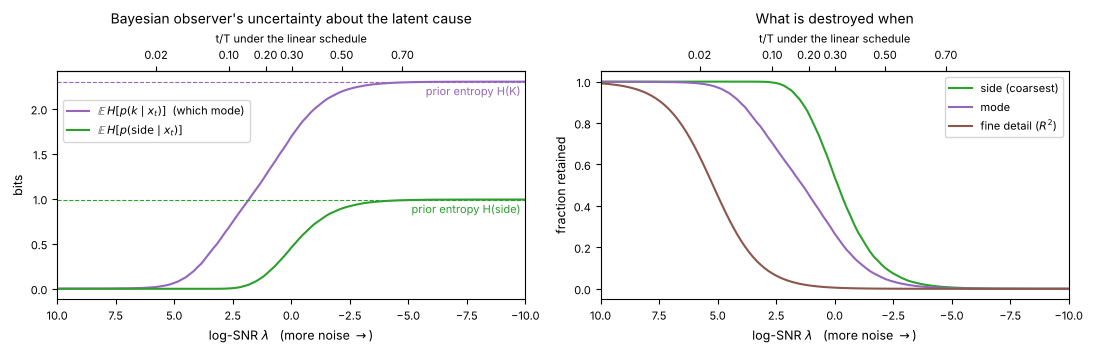

In [15]:
lam_np = lams.numpy()
lam_lin = log_snr(abar_lin[1:]).numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(lam_np, Hk_t, color="tab:purple", label=r"$\mathbb{E}\,H[p(k\mid x_t)]$  (which mode)")
ax.plot(lam_np, Hside_t, color="tab:green", label=r"$\mathbb{E}\,H[p(\mathrm{side}\mid x_t)]$")
ax.axhline(H_k, color="tab:purple", ls="--", lw=0.8)
ax.axhline(H_side, color="tab:green", ls="--", lw=0.8)
ax.text(-9.8, H_k - 0.15, "prior entropy H(K)", color="tab:purple", ha="right", fontsize=8)
ax.text(-9.8, H_side - 0.15, "prior entropy H(side)", color="tab:green", ha="right", fontsize=8)
ax.set(xlabel=r"log-SNR $\lambda$   (more noise $\rightarrow$)", ylabel="bits",
       title="Bayesian observer's uncertainty about the latent cause")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.9))
ax = axes[1]
ax.plot(lam_np, 1 - Hside_t / H_side, color="tab:green", label="side (coarsest)")
ax.plot(lam_np, 1 - Hk_t / H_k, color="tab:purple", label="mode")
ax.plot(lam_np, r2_fine, color="tab:brown", label=r"fine detail ($R^2$)")
ax.set(xlabel=r"log-SNR $\lambda$   (more noise $\rightarrow$)", ylabel="fraction retained",
       title="What is destroyed when")
ax.legend(loc="upper right")
for ax in axes:
    ax.set_xlim(10, -10)          # noise increases to the right, like t
    # secondary axis: the t/T at which the *linear* schedule reaches this log-SNR
    sec = ax.secondary_xaxis("top", functions=(lambda l: np.interp(-l, -lam_lin, np.arange(1, T + 1) / T),
                                               lambda f: np.interp(f, np.arange(1, T + 1) / T, lam_lin)))
    sec.set_xticks([0.02, 0.1, 0.2, 0.3, 0.5, 0.7])
    sec.set_xlabel("t/T under the linear schedule", fontsize=8)
plt.tight_layout()
plt.show()

Reading the right panel from left to right (increasing noise): the **fine detail** (where exactly inside a mode
the point was) is lost first, at high SNR. **Which mode** goes next. **Which side** survives until the SNR
drops to about 1. Noise destroys information from fine to coarse, so the reverse process must
*create* it **from coarse to fine**: early (high-noise) denoising steps decide the global layout (which
side, which mode), and late (low-noise) steps fill in detail. Look for this order whenever you watch a
sampling trajectory in later notebooks.

Natural images have the same structure, with spatial frequencies playing the role of the hierarchy.
Their power spectrum falls steeply with frequency, while Gaussian noise is *white* (flat spectrum). With an
orthonormal FFT, $x_t$ has expected power $\bar\alpha_t P_{\text{data}}(f) + (1-\bar\alpha_t)$ at frequency $f$. The
frequencies where $\bar\alpha_t P_{\text{data}}(f)$ falls below the noise floor are drowned, and as $t$ grows this
cut-off moves from high to low frequencies (Dieleman, "Diffusion is spectral autoregression", 2024).

white-noise power per frequency ring: min 0.93, max 1.02 (expected ~1)


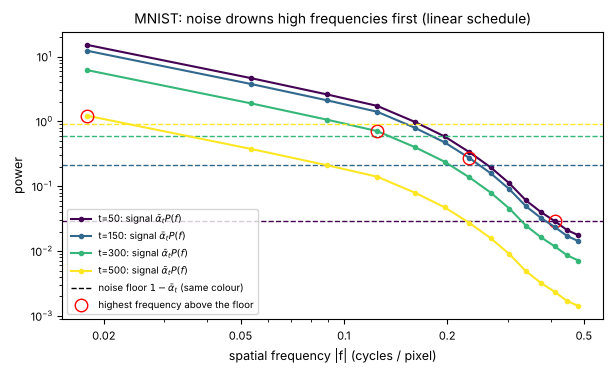

In [16]:
def radial_power_spectrum(imgs, n_bins=14):
    """Mean |FFT|^2 (orthonormal FFT, so unit white noise has power 1) averaged over rings of |f|."""
    F = torch.fft.fft2(imgs[:, 0].double(), norm="ortho")
    P = (F.abs() ** 2).mean(0)
    H, W = P.shape
    fy, fx = torch.fft.fftfreq(H, dtype=torch.float64), torch.fft.fftfreq(W, dtype=torch.float64)
    r = torch.sqrt(fy[:, None] ** 2 + fx[None] ** 2)
    edges = torch.linspace(0, 0.5, n_bins + 1, dtype=torch.float64)
    centres, power = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (r > lo) & (r <= hi)                     # excludes the DC term (r = 0)
        centres.append(((lo + hi) / 2).item())
        power.append(P[m].mean().item())
    return np.array(centres), np.array(power)


n_img = 500 if FAST else 5000
f_c, P_data = radial_power_spectrum(x_test[:n_img])
# sanity check of the normalisation: white noise has power ~1 at every frequency
_, P_white = radial_power_spectrum(torch.randn(200, 1, 28, 28))
print(f"white-noise power per frequency ring: min {P_white.min():.2f}, max {P_white.max():.2f} (expected ~1)")

spec_t = [50, 150, 300, 500]
cmap_t = plt.get_cmap("viridis")
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for i, t in enumerate(spec_t):
    a = abar_lin[t].item()
    col = cmap_t(i / (len(spec_t) - 1))
    ax.plot(f_c, a * P_data, "-o", ms=3, color=col, label=rf"t={t}: signal $\bar\alpha_t P(f)$")
    if t > 0:
        ax.axhline(1 - a, color=col, ls="--", lw=1)
        above = a * P_data > (1 - a)
        if above.any() and not above.all():
            f_cut = f_c[np.where(above)[0].max()]
            ax.plot(f_cut, a * P_data[np.where(above)[0].max()], "o", ms=9, mfc="none", mec="r")
ax.plot([], [], "k--", lw=1, label=r"noise floor $1-\bar\alpha_t$ (same colour)")
ax.plot([], [], "o", ms=9, mfc="none", mec="r", label="highest frequency above the floor")
ax.set(xscale="log", yscale="log", xlabel="spatial frequency |f| (cycles / pixel)", ylabel="power",
       title="MNIST: noise drowns high frequencies first (linear schedule)")
ax.set_xticks([0.02, 0.05, 0.1, 0.2, 0.5], labels=["0.02", "0.05", "0.1", "0.2", "0.5"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

Each solid curve is the digits' power spectrum scaled by $\bar\alpha_t$. Each dashed line is the
(flat) noise power at the same $t$. Frequencies whose signal lies below their dashed line are lost,
and the red circles (the highest surviving frequency) move left as $t$ grows. Stroke edges and fine
detail disappear first; the low-frequency "blob" that fixes the digit's overall shape survives
longest. As in the GMM, generation then proceeds coarse to fine.

## 7 · The reverse posterior $q(x_{t-1}\mid x_t, x_0)$

To generate data we need the reverse step $q(x_{t-1}\mid x_t)$. By Bayes' rule it is
$\propto q(x_t\mid x_{t-1})\,q_{t-1}(x_{t-1})$, which involves the unknown data distribution through
$q_{t-1}$, so it is intractable. If we **also condition on $x_0$**, however, every factor is a known
Gaussian. By the Markov property $q(x_t\mid x_{t-1},x_0)=q(x_t\mid x_{t-1})$, so

$$q(x_{t-1}\mid x_t,x_0)=\frac{q(x_t\mid x_{t-1})\;q(x_{t-1}\mid x_0)}{q(x_t\mid x_0)}
\;\propto\;\underbrace{\mathcal N\big(x_t;\sqrt{\alpha_t}\,x_{t-1},\beta_t\big)}_{\text{likelihood of }x_{t-1}}\;
\underbrace{\mathcal N\big(x_{t-1};\sqrt{\bar\alpha_{t-1}}\,x_0,\,1-\bar\alpha_{t-1}\big)}_{\text{prior on }x_{t-1}} .$$

**Completing the square** (per coordinate). Collect the terms of the log-density that involve $x_{t-1}$:

$$-\frac12\Big[\frac{(x_t-\sqrt{\alpha_t}x_{t-1})^2}{\beta_t}+\frac{(x_{t-1}-\sqrt{\bar\alpha_{t-1}}x_0)^2}{1-\bar\alpha_{t-1}}\Big]
= -\frac12\Big[\underbrace{\Big(\frac{\alpha_t}{\beta_t}+\frac{1}{1-\bar\alpha_{t-1}}\Big)}_{\text{precision } 1/\tilde\beta_t}x_{t-1}^2
-2\underbrace{\Big(\frac{\sqrt{\alpha_t}}{\beta_t}x_t+\frac{\sqrt{\bar\alpha_{t-1}}}{1-\bar\alpha_{t-1}}x_0\Big)}_{\text{precision}\times\text{mean}}x_{t-1}\Big]+\text{const}.$$

Over a common denominator the precision is $\frac{\alpha_t(1-\bar\alpha_{t-1})+\beta_t}{\beta_t(1-\bar\alpha_{t-1})}$, and the numerator
simplifies: $\alpha_t-\bar\alpha_t+1-\alpha_t=1-\bar\alpha_t$. Hence

$$\boxed{\;q(x_{t-1}\mid x_t,x_0)=\mathcal N\big(\tilde\mu_t,\tilde\beta_t I\big),\quad
\tilde\beta_t=\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t,\quad
\tilde\mu_t=\frac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\,x_0+\frac{\sqrt{\alpha_t}\,(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\,x_t\;}$$

This is a precision-weighted average of what the prior says ($x_0$) and what the observation says ($x_t$), the
same structure as a Kalman-filter update. Substituting $x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\varepsilon)/\sqrt{\bar\alpha_t}$ (the closed form of
section 3) gives the form used by DDPM samplers:

$$\tilde\mu_t=\frac{1}{\sqrt{\alpha_t}}\Big(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon\Big).$$

**Why this is THE key quantity.** The DDPM objective is a variational bound whose terms are
$\mathrm{KL}\big(q(x_{t-1}\mid x_t,x_0)\,\|\,p_\theta(x_{t-1}\mid x_t)\big)$. With a Gaussian model
$p_\theta=\mathcal N(\mu_\theta(x_t,t),\sigma_t^2 I)$ and fixed $\sigma_t$, each KL reduces to $\|\tilde\mu_t-\mu_\theta\|^2$ (up to a
scale factor and an additive constant). Because
$\tilde\mu_t$ is linear in $x_0$, or equivalently in $\varepsilon$, the network can instead predict $x_0$ or the noise
$\varepsilon$. This is the $\varepsilon$-prediction loss of notebook 02. Moreover the true reverse step is a
mixture of these Gaussians, $q(x_{t-1}\mid x_t)=\mathbb E_{x_0\sim q(x_0\mid x_t)}\big[q(x_{t-1}\mid x_t,x_0)\big]$, so its mean is $\tilde\mu_t$
with $x_0$ replaced by $\mathbb E[x_0\mid x_t]$ (Tweedie's formula, notebook 03).

In [17]:
def posterior_coefs(betas, abar):
    """Coefficients of q(x_{t-1} | x_t, x_0) = N(c_x0[t] x0 + c_xt[t] x_t, var[t]), for t = 1..T.

    Index 0 is undefined (there is no x_{-1}) and is set to NaN.
    """
    alphas = 1 - betas
    abar_prev = torch.cat([torch.ones(1, dtype=abar.dtype), abar[:-1]])    # abar_{t-1}
    c_x0 = betas * abar_prev.sqrt() / (1 - abar)
    c_xt = alphas.sqrt() * (1 - abar_prev) / (1 - abar)
    var = betas * (1 - abar_prev) / (1 - abar)
    for v in (c_x0, c_xt, var):
        v[0] = float("nan")
    return c_x0, c_xt, var


c_x0, c_xt, post_var = posterior_coefs(betas_lin, abar_lin)
# --- CHECK 1: dmtools' coefficients (index shifted by one) -----------------------------------
assert torch.allclose(c_x0[1:].float(), dm_sched.posterior_coef_x0.cpu(), rtol=1e-4, atol=1e-7)
assert torch.allclose(c_xt[1:].float(), dm_sched.posterior_coef_xt.cpu(), rtol=1e-4, atol=1e-7)
assert torch.allclose(post_var[1:].float(), dm_sched.posterior_variance.cpu(), rtol=1e-4, atol=1e-9)
print("posterior coefficients match dm.NoiseSchedule.posterior_*")
print(f"at t = 1: c_x0 = {c_x0[1]:.3f}, c_xt = {c_xt[1]:.3f}, variance = {post_var[1]:.1e} "
      "(x_0 is known exactly, so the last reverse step must add no noise)")

# --- CHECK 2: the two forms of the posterior mean agree ----------------------------------------
t_ = 400
x0_c = x0_1d[:1000].double()
eps_c = torch.randn_like(x0_c)
xt_c = abar_lin[t_].sqrt() * x0_c + (1 - abar_lin[t_]).sqrt() * eps_c
mu_x0_form = c_x0[t_] * x0_c + c_xt[t_] * xt_c
mu_eps_form = (xt_c - betas_lin[t_] / (1 - abar_lin[t_]).sqrt() * eps_c) / (1 - betas_lin[t_]).sqrt()
assert torch.allclose(mu_x0_form, mu_eps_form, atol=1e-10)
print("x0-form and eps-form of mu_tilde agree")

posterior coefficients match dm.NoiseSchedule.posterior_*
at t = 1: c_x0 = 1.000, c_xt = 0.000, variance = 0.0e+00 (x_0 is known exactly, so the last reverse step must add no noise)
x0-form and eps-form of mu_tilde agree


**Monte Carlo check.** The formula holds for any step size, so we test it where it is least
trivial: a coarse 10-step schedule (respaced from the linear one) whose $\beta$'s are large. We sample
$x_0$ from the 1-D mixture, then $x_{t-1}\sim q(x_{t-1}\mid x_0)$, then one forward step to get $x_t$. Since
$(x_{t-1},x_t)$ is jointly Gaussian given $x_0$, a **least-squares regression** of $x_{t-1}$ on $(x_0,x_t)$ must
recover the coefficients of $\tilde\mu_t$ exactly, and its residual variance must equal $\tilde\beta_t$.

In [18]:
betas_10, abar_10 = respace(abar_lin, 10)
c_x0_10, c_xt_10, var_10 = posterior_coefs(betas_10, abar_10)
n_reg = 20_000 if FAST else 400_000
x0_r = gmm1d.sample(n_reg).double()[:, 0]
print(f"{'t':>2} {'beta_t':>7} | {'coef x0: MC / formula':>22} | {'coef x_t: MC / formula':>23} | "
      f"{'variance: MC / formula':>23}")
for t in range(1, 11):
    x_prev = abar_10[t - 1].sqrt() * x0_r + (1 - abar_10[t - 1]).sqrt() * torch.randn(n_reg, dtype=torch.float64)
    x_t = (1 - betas_10[t]).sqrt() * x_prev + betas_10[t].sqrt() * torch.randn(n_reg, dtype=torch.float64)
    A = torch.stack([x0_r, x_t], 1)
    coef = torch.linalg.lstsq(A, x_prev[:, None]).solution[:, 0]
    resid_var = (x_prev - A @ coef).var().item()
    print(f"{t:2d} {betas_10[t]:7.3f} | {coef[0]:9.4f} / {c_x0_10[t]:9.4f} | {coef[1]:10.4f} / {c_xt_10[t]:9.4f} | "
          f"{resid_var:10.4f} / {var_10[t]:9.4f}")
    if not FAST:
        assert abs(coef[0] - c_x0_10[t]) < 0.01 and abs(coef[1] - c_xt_10[t]) < 0.01
        assert abs(resid_var - var_10[t].item()) <= 0.02 * var_10[t].item() + 1e-6   # var = 0 at t = 1

 t  beta_t |  coef x0: MC / formula |  coef x_t: MC / formula |  variance: MC / formula


 1   0.103 |    1.0000 /    1.0000 |     0.0000 /    0.0000 |     0.0000 /    0.0000


 2   0.265 |    0.7359 /    0.7369 |     0.2595 /    0.2589 |     0.0798 /    0.0801


 3   0.398 |    0.5360 /    0.5360 |     0.4386 /    0.4381 |     0.2252 /    0.2251


 4   0.508 |    0.3971 /    0.3972 |     0.5263 /    0.5262 |     0.3800 /    0.3808


 5   0.597 |    0.2863 /    0.2864 |     0.5547 /    0.5543 |     0.5192 /    0.5217


 6   0.671 |    0.1940 /    0.1930 |     0.5419 /    0.5428 |     0.6333 /    0.6344


 7   0.731 |    0.1175 /    0.1184 |     0.5096 /    0.5089 |     0.7152 /    0.7169


 8   0.780 |    0.0645 /    0.0652 |     0.4653 /    0.4664 |     0.7759 /    0.7758


 9   0.820 |    0.0328 /    0.0321 |     0.4245 /    0.4233 |     0.8194 /    0.8193


10   0.853 |    0.0143 /    0.0142 |     0.3817 /    0.3829 |     0.8556 /    0.8532


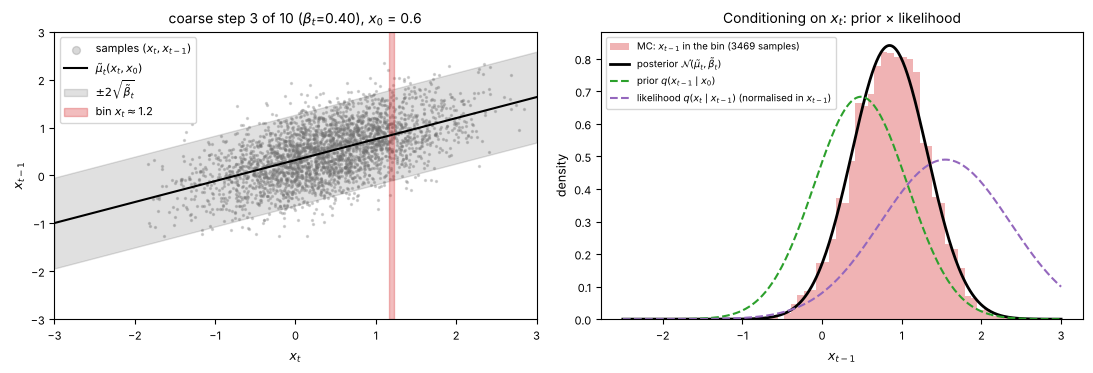

In [19]:
# Visualise one coarse step for a fixed x_0: prior x likelihood -> posterior
t, x0_fix = 3, 0.6
a_prev, a_t, b_t = abar_10[t - 1].item(), abar_10[t].item(), betas_10[t].item()
n_vis = 20_000 if FAST else 200_000
x_prev = math.sqrt(a_prev) * x0_fix + math.sqrt(1 - a_prev) * torch.randn(n_vis, dtype=torch.float64)
x_t = math.sqrt(1 - b_t) * x_prev + math.sqrt(b_t) * torch.randn(n_vis, dtype=torch.float64)
mu = lambda xt: c_x0_10[t].item() * x0_fix + c_xt_10[t].item() * xt
sd = math.sqrt(var_10[t].item())
gauss = lambda x, m, s: np.exp(-0.5 * ((x - m) / s) ** 2) / (s * math.sqrt(2 * math.pi))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.scatter(x_t[:3000], x_prev[:3000], s=2, alpha=0.3, color="gray", label="samples $(x_t, x_{t-1})$")
xs = np.linspace(-3, 3, 100)
ax.plot(xs, mu(xs), color=C_THEORY, label=r"$\tilde\mu_t(x_t, x_0)$")
ax.fill_between(xs, mu(xs) - 2 * sd, mu(xs) + 2 * sd, color=C_THEORY, alpha=0.12, label=r"$\pm 2\sqrt{\tilde\beta_t}$")
x_bin = 1.2
ax.axvspan(x_bin - 0.03, x_bin + 0.03, color="tab:red", alpha=0.3, label=f"bin $x_t\\approx${x_bin}")
ax.set(xlim=(-3, 3), ylim=(-3, 3), xlabel="$x_t$", ylabel="$x_{t-1}$",
       title=rf"coarse step {t} of 10 ($\beta_t$={b_t:.2f}), $x_0$ = {x0_fix}")
ax.legend(loc="upper left", markerscale=4)
ax = axes[1]
sel = (x_t - x_bin).abs() < 0.03
ax.hist(x_prev[sel].numpy(), bins=40, density=True, color="tab:red", alpha=0.35,
        label=f"MC: $x_{{t-1}}$ in the bin ({sel.sum().item()} samples)")
xs = np.linspace(-2.5, 3, 400)
ax.plot(xs, gauss(xs, mu(x_bin), sd), color=C_THEORY, lw=2, label=r"posterior $\mathcal{N}(\tilde\mu_t,\tilde\beta_t)$")
ax.plot(xs, gauss(xs, math.sqrt(a_prev) * x0_fix, math.sqrt(1 - a_prev)), "--", color="tab:green",
        label=r"prior $q(x_{t-1}\mid x_0)$")
ax.plot(xs, gauss(xs, x_bin / math.sqrt(1 - b_t), math.sqrt(b_t / (1 - b_t))), "--", color="tab:purple",
        label=r"likelihood $q(x_t\mid x_{t-1})$ (normalised in $x_{t-1}$)")
ax.set(xlabel="$x_{t-1}$", ylabel="density", title="Conditioning on $x_t$: prior × likelihood")
ax.legend(loc="upper left", fontsize=7)
plt.tight_layout()
plt.show()

**Left:** given $x_0$, the pairs $(x_t, x_{t-1})$ form a Gaussian cloud whose conditional mean is the
straight line $\tilde\mu_t$ and whose spread is $\tilde\beta_t$. **Right:** the samples whose $x_t$ falls into a
narrow bin match the predicted posterior. The posterior lies between the prior (from $x_0$) and the
likelihood (from $x_t$), and is narrower than both, as in any conjugate Gaussian update.

## 8 · Why small steps matter: the reverse step is (nearly) Gaussian only when $\beta_t$ is small

The reverse model in notebook 02 is a Gaussian $p_\theta(x_{t-1}\mid x_t)=\mathcal N(\mu_\theta,\sigma_t^2I)$. Is that
justified? The true reverse step, **without** $x_0$, is again "prior × likelihood":

$$q(x_{t-1}\mid x_t)\;\propto\;\underbrace{q(x_t\mid x_{t-1})}_{\mathcal N(x_t;\sqrt{\alpha_t}x_{t-1},\,\beta_t):\ \text{width}\ \sim\sqrt{\beta_t}}\;\;\underbrace{q_{t-1}(x_{t-1})}_{\text{noised data: anything}} .$$

If $\beta_t$ is **small**, the likelihood is a narrow window, and over that window $\log q_{t-1}$ is almost linear.
A Gaussian times $e^{\text{linear}}$ is a Gaussian, so the posterior is nearly Gaussian. Expanding $\log q_{t-1}$
to third order, the leading non-Gaussian term is a skewness of order $\beta_t^{3/2}$, so the KL to the best
Gaussian should vanish like $\beta_t^3$. If $\beta_t$ is **large**, the window is wide and the posterior inherits
the multimodality of $q_{t-1}$; no Gaussian can represent it.

We can compute this *exactly* in 1-D: $q_{t-1}$ is the noised GMM, so we evaluate prior × likelihood on a fine
grid and normalise. We fix the noise level of $x_t$ ($t/T=0.3$ on the linear schedule) and vary how far back
the previous level is: one step back corresponds to $T=1000$, 200 steps back to a coarse $T=5$ schedule.
The "best Gaussian" is the moment-matched one. It minimises $\mathrm{KL}(q\,\|\,\mathcal N)$, and it is what a
Gaussian reverse model trained on the variational bound would converge to if both its mean and its variance
are learned.

In [20]:
def log_density64(gmm, x):
    """float64 log q(x) of a GMM (dmtools' log_prob returns float32, too coarse for tiny KLs)."""
    return torch.logsumexp(gmm.component_log_probs(x), dim=1)


def reverse_conditional(abar_prev, abar_t, x_t, grid):
    """Exact q(x_{t-1} | x_t) for the 1-D mixture on `grid`: log-density, shape (len(x_t), len(grid))."""
    alpha = abar_t / abar_prev                                       # one (possibly large) step
    log_prior = log_density64(gmm1d.noised(abar_prev), grid[:, None])            # log q_{t-1}
    log_lik = -0.5 * (x_t[:, None] - math.sqrt(alpha) * grid[None]) ** 2 / (1 - alpha)
    logp = log_prior[None] + log_lik
    dx = (grid[1] - grid[0]).item()
    return logp - torch.logsumexp(logp, 1, keepdim=True) - math.log(dx)          # normalised density


def gaussian_fit_and_kl(logp, grid):
    """Moment-matched Gaussian (mean, var) of each row, and KL(q || that Gaussian) in nats."""
    dx = (grid[1] - grid[0]).item()
    p = logp.exp()
    m = (p * grid).sum(1) * dx
    v = (p * (grid - m[:, None]) ** 2).sum(1) * dx
    neg_entropy = (p * logp).sum(1) * dx
    return m, v, neg_entropy + 0.5 * torch.log(2 * math.pi * math.e * v)


grid_r = torch.linspace(-5, 5, 4001 if FAST else 20001, dtype=torch.float64)
t_target = 300
x_t_show = torch.tensor([-0.7, 0.2, 1.0], dtype=torch.float64)
cases = [("coarse: 200 steps back (T≈5)", 200), ("fine: 1 step back (T=1000)", 1)]
cond = {}
for label, back in cases:
    a_prev, a_t = abar_lin[t_target - back].item(), abar_lin[t_target].item()
    lp = reverse_conditional(a_prev, a_t, x_t_show, grid_r)
    cond[back] = (lp, *gaussian_fit_and_kl(lp, grid_r), 1 - a_t / a_prev)

# KL averaged over x_t ~ q_t, as a function of the step size
backs = [200, 20, 1] if FAST else [300, 200, 100, 50, 20, 10, 5, 2, 1]
n_xt = 50 if FAST else 300
x_t_samples = gmm1d.noised(abar_lin[t_target].item()).sample(n_xt).double()[:, 0]
kl_mean, beta_step = [], []
for back in backs:
    a_prev, a_t = abar_lin[t_target - back].item(), abar_lin[t_target].item()
    _, _, kl = gaussian_fit_and_kl(reverse_conditional(a_prev, a_t, x_t_samples, grid_r), grid_r)
    kl_mean.append(kl.mean().item())
    beta_step.append(1 - a_t / a_prev)
kl_mean, beta_step = np.array(kl_mean), np.array(beta_step)
for back, b, k in zip(backs, beta_step, kl_mean):
    print(f"step from t={t_target - back:3d} to t={t_target} (equiv. T≈{1000 / back:6.1f}): beta = {b:.4f}, "
          f"mean KL(q || best Gaussian) = {k:.2e} nats")
small = beta_step < 0.15
slope = np.polyfit(np.log(beta_step[small]), np.log(kl_mean[small]), 1)[0]
print(f"log-log slope of KL vs beta for small steps: {slope:.2f} (theory: 3)")

step from t=  0 to t=300 (equiv. T≈   3.3): beta = 0.6036, mean KL(q || best Gaussian) = 1.04e+00 nats
step from t=100 to t=300 (equiv. T≈   5.0): beta = 0.5581, mean KL(q || best Gaussian) = 1.81e-01 nats
step from t=200 to t=300 (equiv. T≈  10.0): beta = 0.3985, mean KL(q || best Gaussian) = 1.61e-02 nats
step from t=250 to t=300 (equiv. T≈  20.0): beta = 0.2436, mean KL(q || best Gaussian) = 1.57e-03 nats
step from t=280 to t=300 (equiv. T≈  50.0): beta = 0.1110, mean KL(q || best Gaussian) = 8.49e-05 nats
step from t=290 to t=300 (equiv. T≈ 100.0): beta = 0.0581, mean KL(q || best Gaussian) = 1.00e-05 nats
step from t=295 to t=300 (equiv. T≈ 200.0): beta = 0.0297, mean KL(q || best Gaussian) = 1.22e-06 nats
step from t=298 to t=300 (equiv. T≈ 500.0): beta = 0.0121, mean KL(q || best Gaussian) = 7.65e-08 nats
step from t=299 to t=300 (equiv. T≈1000.0): beta = 0.0061, mean KL(q || best Gaussian) = 9.51e-09 nats
log-log slope of KL vs beta for small steps: 3.12 (theory: 3)


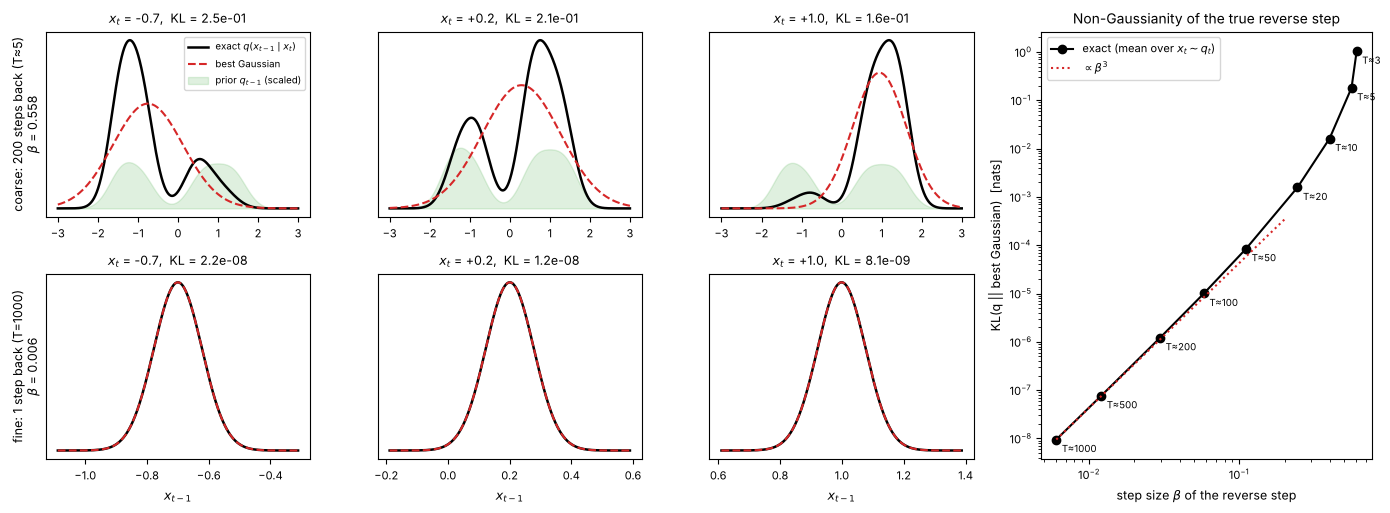

In [21]:
fig = plt.figure(figsize=(14, 5.2))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 1.25])
for row, (label, back) in enumerate(cases):
    lp, m, v, kl, b = cond[back]
    for j, xt in enumerate(x_t_show.tolist()):
        ax = fig.add_subplot(gs[row, j])
        sd_ = math.sqrt(v[j].item())
        lo, hi = (-3.0, 3.0) if back > 1 else (m[j].item() - 5 * sd_, m[j].item() + 5 * sd_)
        sel = (grid_r >= lo) & (grid_r <= hi)
        gx = grid_r[sel].numpy()
        ax.plot(gx, lp[j, sel].exp().numpy(), color="k", lw=1.8, label=r"exact $q(x_{t-1}\mid x_t)$")
        ax.plot(gx, gauss(gx, m[j].item(), sd_), "--", color="tab:red", lw=1.5, label="best Gaussian")
        if back > 1:   # show where the modes come from: the prior q_{t-1}
            prior = log_density64(gmm1d.noised(abar_lin[t_target - back].item()), grid_r[sel][:, None]).exp()
            ax.fill_between(gx, prior.numpy() * 0.5, color="tab:green", alpha=0.15, label=r"prior $q_{t-1}$ (scaled)")
        ax.set_title(f"$x_t$ = {xt:+.1f},  KL = {kl[j]:.1e}", fontsize=9)
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(f"{label}\n" + rf"$\beta$ = {b:.3f}", fontsize=9)
        if row == 1:
            ax.set_xlabel("$x_{t-1}$")
        if row == 0 and j == 0:
            ax.legend(fontsize=7, loc="upper right")
ax = fig.add_subplot(gs[:, 3])
ax.loglog(beta_step, kl_mean, "o-", color="k", label="exact (mean over $x_t\\sim q_t$)")
ref_b = np.array([beta_step.min(), 0.2])
ax.loglog(ref_b, kl_mean[-1] * (ref_b / beta_step[-1]) ** 3, ":", color="tab:red", label=r"$\propto\beta^3$")
for back, b, k in zip(backs, beta_step, kl_mean):
    ax.annotate(f"T≈{1000 / back:.0f}", (b, k), textcoords="offset points", xytext=(4, -9), fontsize=7)
ax.set(xlabel=r"step size $\beta$ of the reverse step", ylabel="KL(q || best Gaussian)  [nats]",
       title="Non-Gaussianity of the true reverse step")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Top row (one big step, $T\approx5$):** the exact reverse conditional is clearly non-Gaussian. It is
multimodal or skewed, because it inherits the modes of the prior $q_{t-1}$ (green), and the
moment-matched Gaussian (red dashed) puts mass where the true distribution has none. A Gaussian reverse
model would generate samples *between* the modes. **Bottom row (one small step, $T=1000$):** for the same $x_t$
the conditional is a narrow bump that a Gaussian matches almost perfectly. **Right:** the KL to the best
Gaussian falls by many orders of magnitude as the step shrinks. For small steps it follows the predicted
$\beta^3$ slope (see the fitted slope printed above); for large steps it rises even faster.

This is the theoretical licence for DDPM's Gaussian reverse steps, and the reason diffusion models need
many steps. Fast samplers (notebook 04), distillation and consistency models are all ways around this
constraint.

## 9 · The "variance exploding" alternative

Score-based models (NCSN, Song & Ermon 2019) and EDM (Karras et al. 2022) use a process that does not
shrink the signal:

$$x_\sigma = x_0+\sigma\,\varepsilon,\qquad \sigma\in[\sigma_{\min},\sigma_{\max}],$$

i.e. the "no shrink" chain of section 2. Its variance explodes ($\approx\sigma^2$), and generation starts from
$\mathcal N(0,\sigma_{\max}^2 I)$, which is a good approximation of $q_{\sigma_{\max}}$ only when $\sigma_{\max}$ is much
larger than the data's diameter (EDM uses $\sigma_{\max}=80$).

**VP and VE are the same process up to a rescaling of $x$.** Divide the VP sample by $\sqrt{\bar\alpha_t}$:

$$\frac{x_t^{\text{VP}}}{\sqrt{\bar\alpha_t}} = x_0 + \sqrt{\frac{1-\bar\alpha_t}{\bar\alpha_t}}\;\varepsilon = x_\sigma^{\text{VE}}
\quad\text{with}\quad \sigma=\sqrt{\frac{1-\bar\alpha_t}{\bar\alpha_t}}=\mathrm{SNR}^{-1/2}=e^{-\lambda/2}.$$

So at matched SNR the densities are related by a change of variables,
$q^{\text{VP}}_t(x)=\bar\alpha_t^{-d/2}\,q^{\text{VE}}_\sigma(x/\sqrt{\bar\alpha_t})$. A network trained for one can be used for
the other once its inputs are rescaled, which is exactly how EDM unifies the two. More generally, any
$x_t=a_t x_0+s_t\varepsilon$ is characterised by its SNR $a_t^2/s_t^2$ (plus an overall scale). Flow matching's
$x_t=(1-t)x_0+t\,\varepsilon$ (notebook 08) is another member of this family.

VP and VE agree up to the rescaling x -> x / sqrt(abar) (samples and exact densities)


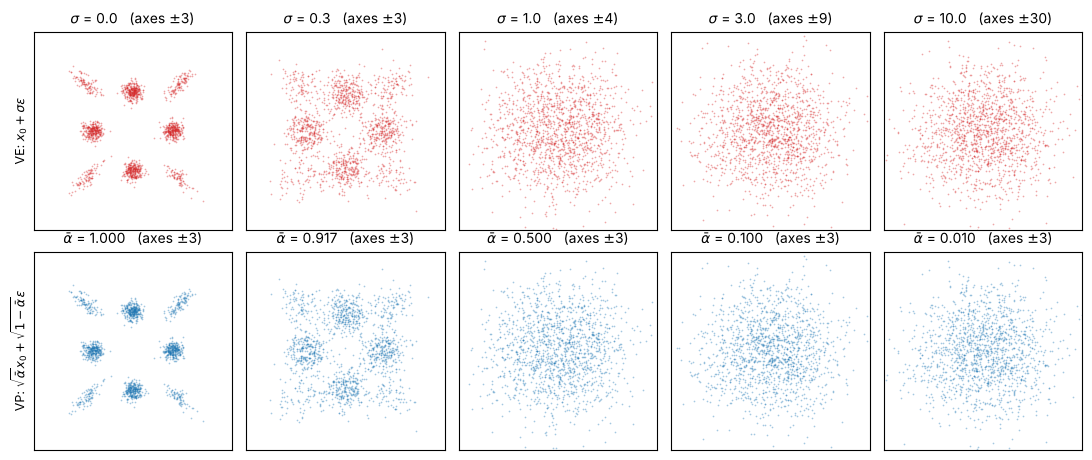

In [22]:
sigmas = [0.0, 0.3, 1.0, 3.0, 10.0]
x0_ve = gmm2d.sample(N)
eps_ve = torch.randn_like(x0_ve)
pts = torch.randn(500, 2, dtype=torch.float64) * 2
for s in sigmas[1:]:
    a = 1 / (1 + s ** 2)                                  # abar with the same SNR as sigma
    # --- CHECK 1: pointwise, VP sample / sqrt(abar) == VE sample (same eps) ---
    vp = math.sqrt(a) * x0_ve + math.sqrt(1 - a) * eps_ve
    ve = x0_ve + s * eps_ve
    assert torch.allclose(vp / math.sqrt(a), ve, rtol=1e-5, atol=1e-4)
    # --- CHECK 2: exact densities related by the change of variables (dm.noised vs dm.noised_ve) ---
    lp_vp = log_density64(gmm2d.noised(a), pts)
    lp_ve = log_density64(gmm2d.noised_ve(s), pts / math.sqrt(a)) - (gmm2d.d / 2) * math.log(a)
    assert torch.allclose(lp_vp, lp_ve, atol=1e-8)
print("VP and VE agree up to the rescaling x -> x / sqrt(abar) (samples and exact densities)")

fig, axes = plt.subplots(2, len(sigmas), figsize=(2.2 * len(sigmas), 4.6))
for j, s in enumerate(sigmas):
    a = 1 / (1 + s ** 2)
    lim_ve = 3 * math.sqrt(1 + s ** 2)
    x0_s, eps_s = x0_ve[:1500], eps_ve[:1500]          # a subset is enough for the picture
    dm.scatter2d(x0_s + s * eps_s, ax=axes[0, j], s=1.5, alpha=0.4, c=C_VE, lim=lim_ve,
                 title=rf"$\sigma$ = {s}   (axes $\pm${lim_ve:.0f})")
    dm.scatter2d(math.sqrt(a) * x0_s + math.sqrt(1 - a) * eps_s, ax=axes[1, j], s=1.5, alpha=0.4, c=C_VP,
                 lim=3, title=rf"$\bar\alpha$ = {a:.3f}   (axes $\pm$3)")
axes[0, 0].set_ylabel("VE: $x_0+\\sigma\\varepsilon$")
axes[1, 0].set_ylabel(r"VP: $\sqrt{\bar\alpha}x_0+\sqrt{1-\bar\alpha}\varepsilon$")
plt.tight_layout()
plt.show()

Each column shows the same noise draw at the same SNR. The two rows are the same picture drawn on
different rulers: the VE cloud keeps the data's size while the noise grows (note the axis ranges),
whereas the VP cloud stays inside $\pm3$ and the data shrink instead. The choice between them matters in
practice (network inputs at very different scales, the starting distribution, numerical precision),
but not in principle.

## Exercises

**Exercise 1 (terminal SNR).** Make the linear schedule end at $\beta_T=0.01$ instead of $0.02$ (`make_schedule("linear", beta_end=0.01)`).
Before running anything, predict $\bar\alpha_T$, and how much of the digit's amplitude survives in $x_T$. Then
re-plot the digit strip of section 4. Why is this a problem when sampling starts from pure $\mathcal N(0,I)$?

<details><summary>Hint / solution</summary>

$\bar\alpha_T\approx\exp(-\sum_t\beta_t)\approx\exp(-T\,\bar\beta)=\exp(-1000\cdot 0.00505)\approx 6\times10^{-3}$, so a fraction
$\sqrt{\bar\alpha_T}\approx 0.08$ of the signal amplitude survives, versus $\approx0.006$ for the standard schedule. During
training the network only ever sees $x_T$ that still carry a faint trace of the data (e.g. the digit's average
brightness), but at sampling time we start from pure noise. This train/test mismatch matters most for
low-frequency statistics such as overall brightness. Check: `print(make_schedule("linear", beta_end=0.01)[1][-1])`.
</details>

**Exercise 2 (data scale is part of the schedule).** Multiply the 1-D mixture by $c=3$ (scale its `means` by $c$ and its `covs`
by $c^2$) and recompute the "what is destroyed when" curves of section 6. Predict how far, and in which direction,
they move along the log-SNR axis.

<details><summary>Hint / solution</summary>

$x_t=\sqrt{\bar\alpha}\,c\,x_0'+\sqrt{1-\bar\alpha}\,\varepsilon$ has an *effective* SNR of $c^2\,\bar\alpha/(1-\bar\alpha)$, so every curve shifts by
$2\log c\approx 2.2$ towards lower $\lambda$ (more noise is needed to destroy the same structure). Scaling the data is
therefore equivalent to shifting the schedule. This is why data normalisation is a real hyper-parameter, e.g. the
latent scale factor in Stable Diffusion (notebook 09), and why high-resolution images, whose redundant pixels
survive noise better, benefit from shifted schedules (Esser et al. 2024).
</details>

**Exercise 3 (design a schedule by its log-SNR).** Define a schedule with $\lambda(\tau)$ *linear* in $\tau=t/T$, from $+10$ to $-10$.
Hint: $\bar\alpha=\operatorname{sigmoid}(\lambda)$, then $\beta_t = 1-\bar\alpha_t/\bar\alpha_{t-1}$. Plot it next to the linear and cosine schedules in
the figure of section 4 and redo the digit strip. Which of the two existing schedules does it resemble more?

<details><summary>Hint / solution</summary>

```python
lam = torch.linspace(10, -10, T + 1, dtype=torch.float64)
abar_ls = torch.sigmoid(lam); abar_ls[0] = 1.0       # t = 0 is the clean data
betas_ls = torch.cat([torch.zeros(1, dtype=torch.float64), 1 - abar_ls[1:] / abar_ls[:-1]])
```
It resembles the cosine schedule, which is close to linear in $\lambda$ over its middle range
($\lambda_{\cos}(\tau)\approx-2\log\tan(\pi\tau/2)$). The linear-$\beta$ schedule instead drops quickly through the informative range.
</details>

**Exercise 4 (jumping between noise levels).** Show that for $s<t$,
$q(x_t\mid x_s)=\mathcal N\big(\sqrt{\bar\alpha_t/\bar\alpha_s}\,x_s,\ (1-\bar\alpha_t/\bar\alpha_s)\,I\big)$, and verify it by Monte Carlo: start
`forward_chain` from samples of $x_s$ with `b = betas_lin[s:].clone(); b[0] = 0`, so that index $k$ of the new chain is
maths time $s+k$. Why does this justify the `respace` function?

<details><summary>Hint / solution</summary>

Repeat the induction of section 3 starting at $x_s$ instead of $x_0$: the product of the $\alpha$'s between $s$ and $t$ is
$\bar\alpha_t/\bar\alpha_s$. `respace` defines a coarse step from level $\tau_{j-1}$ to $\tau_j$ with $\beta=1-\bar\alpha_{\tau_j}/\bar\alpha_{\tau_{j-1}}$, which is exactly
this composite kernel. A coarse chain therefore has *the same marginals* $q_{\tau_j}$ as the fine chain; only the
reverse conditionals differ (section 8).
</details>

**Exercise 5 (where do big steps hurt most?).** In section 8, keep a large step (`back = 100`) and move the target noise
level `t_target` through 100, 200, 400, 700. Predict first: at which noise levels does a coarse reverse step
deviate most from a Gaussian?

<details><summary>Hint / solution</summary>

The KL is largest at **low** noise (small `t_target`), where $q_{t-1}$ still has sharp, well-separated modes inside the
likelihood window. It becomes negligible at high noise, where $q_{t-1}$ is itself nearly Gaussian. This is why
few-step samplers struggle mostly with fine detail, and why step-size schedules for samplers (e.g. EDM's)
concentrate steps at low noise.
</details>

## Key takeaways

- The forward process is a **fixed** Markov chain of small Gaussian steps $x_t=\sqrt{1-\beta_t}\,x_{t-1}+\sqrt{\beta_t}\,\varepsilon$. The shrink factor
  keeps the variance at 1 (VP) and guarantees $x_T\approx\mathcal N(0,I)$ for any data of roughly unit scale.
- Closed form: $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon$. Training samples any $t$ directly and knows the exact noise $\varepsilon$ it added.
- A schedule is best described by its **log-SNR curve** $\lambda_t=\log\frac{\bar\alpha_t}{1-\bar\alpha_t}$. The marginals depend on $t$ only through $\lambda_t$;
  the schedule decides how steps are spread over noise levels. Linear wastes steps on pure noise; cosine spreads them evenly.
- For a GMM the noised marginal $q_t$ is an exact GMM. This gives a ground-truth laboratory used in the rest of the tutorial.
- Noise destroys **fine detail first and coarse structure last** (GMM hierarchy; image frequencies), so generation runs coarse to fine.
- $q(x_{t-1}\mid x_t,x_0)=\mathcal N(\tilde\mu_t,\tilde\beta_t I)$ follows from Gaussian conjugacy. $\tilde\mu_t$ is linear in $x_0$ (or $\varepsilon$), which is why
  networks predict the noise. It is the training target of notebook 02.
- The true reverse step $q(x_{t-1}\mid x_t)$ is Gaussian only for **small** $\beta_t$ (KL $\propto\beta^3$). That is why diffusion uses many steps.
- Implementation gotchas: maths $t$ vs 0-based array index (dmtools `t` = maths $t-1$), broadcasting `(B,)` coefficients
  over data dimensions, clipping the cosine $\beta_T$, nonzero terminal SNR, and data scale.
- VE ($x_0+\sigma\varepsilon$) and VP are the same process up to rescaling $x$ by $\sqrt{\bar\alpha}$, with $\sigma=e^{-\lambda/2}$.

## Further reading

- J. Sohl-Dickstein, E. Weiss, N. Maheswaranathan, S. Ganguli (2015). *Deep Unsupervised Learning using Nonequilibrium Thermodynamics.* arXiv:1503.03585. The original diffusion model, including the small-step Gaussian argument.
- J. Ho, A. Jain, P. Abbeel (2020). *Denoising Diffusion Probabilistic Models.* arXiv:2006.11239. The linear schedule, $q(x_{t-1}\mid x_t,x_0)$ and $\varepsilon$-prediction.
- A. Nichol, P. Dhariwal (2021). *Improved Denoising Diffusion Probabilistic Models.* arXiv:2102.09672. The cosine schedule.
- D. Kingma, T. Salimans, B. Poole, J. Ho (2021). *Variational Diffusion Models.* arXiv:2107.00630. The SNR view of schedules.
- Y. Song, J. Sohl-Dickstein, D. Kingma, A. Kumar, S. Ermon, B. Poole (2021). *Score-Based Generative Modeling through Stochastic Differential Equations.* arXiv:2011.13456. The VP and VE SDEs.
- Y. Song, S. Ermon (2019). *Generative Modeling by Estimating Gradients of the Data Distribution.* arXiv:1907.05600. VE noise (NCSN).
- T. Karras, M. Aittala, T. Aila, S. Laine (2022). *Elucidating the Design Space of Diffusion-Based Generative Models.* arXiv:2206.00364. The $\sigma$ parametrisation and its unification of VP and VE.
- P. Esser et al. (2024). *Scaling Rectified Flow Transformers for High-Resolution Image Synthesis* (SD3). arXiv:2403.03206. Includes resolution-dependent schedule shifting.
- L. Weng (2021). *What are Diffusion Models?* lilianweng.github.io. A compact derivation-heavy overview.
- S. Dieleman (2024). *Diffusion is spectral autoregression.* sander.ai. The coarse-to-fine / frequency view of section 6.